# Mini-Challenge DEL: Hyperparameter Tuning und Model Evaluation

In [1]:
# Standard library imports
import itertools
from pathlib import Path
import sys

# Third-party imports
import sys
import os
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
import seaborn as sns 
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate
from skorch import NeuralNetClassifier
import torch
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from tqdm import tqdm
import wandb

sys.path.append(os.path.abspath("../src"))


In [2]:
from deeplearning.training import run_baseline, RunConfig, FitConfig
from deeplearning.wandb_tools import WandbRuns
from deeplearning.model import BaselineCNN

In [3]:
# General Configurations
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

# Wandb Configurations
wandb_runs = WandbRuns(project="DEL", entity="lukas-breiter-fachhochschule-nordwestschweiz-fhnw")
project_path = (f"{wandb_runs.entity}/{wandb_runs.project}")
api = wandb.Api()


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


## Erste Etappe: Daten Kennenlernen, Aufbau Modellierung & Basismodell
In dieser Phase legst du das Fundament für dein Deep Learning Projekt. Ziel ist es, die Daten zu verstehen, eine stabile Trainings-Pipeline aufzubauen und die Performance eines einfachen Basismodells als Referenzwert zu ermitteln.

### 1. Vorbereitung der Daten

* a) Explorative Analyse: Führe eine kurze Analyse der Features durch. Untersuche dabei insbesondere:
* Den Vergleich der Klassen pro Feature.
   * Die Balanciertheit der Klassen (Class Balance).
* b) Preprocessing: Implementiere geeignete Vorverarbeitungsschritte (z. B. Normalisierung oder Standardisierung der Daten).

#### Explorative Analyse


In [4]:
# Laden des svhn
def load_svhn_data(batch_size=64):
    transform = transforms.Compose([
        transforms.ToTensor(),        
    ])

    train_dataset = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
    test_dataset = datasets.SVHN(root='../data', split='test', download=True, transform=transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader

train_loader, test_loader = load_svhn_data()

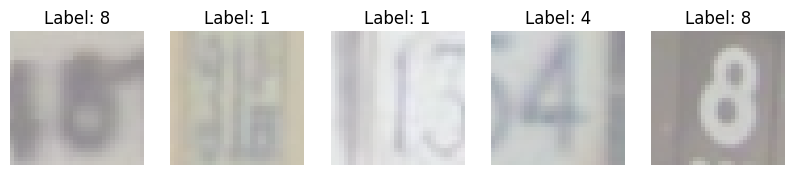

In [5]:
# EDA: Visualize some samples from the dataset
data_iter = iter(train_loader)
num_samples_to_show = 5

images, labels = next(data_iter)

plt.figure(figsize=(10, 2))
for i in range(num_samples_to_show):
    plt.subplot(1, num_samples_to_show, i + 1)
    plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)) * 0.5 + 0.5)
    plt.title(f'Label: {labels[i].item()}')
    plt.axis('off')
plt.show()


Die Bilder sehen gut aus, es sind Google Maps screenshots von Hausnummern.

In [6]:
# EDA: 

def prepare_labels(dataset):
    labels = np.array(dataset.labels)
    labels = np.where(labels == 10, 0, labels)
    return labels

# EDA für Train und Test
train_labels = prepare_labels(train_loader.dataset)
test_labels = prepare_labels(test_loader.dataset)

In [7]:
# Klassen-Balanciertheit

def class_dist(labels):
    # Klassenverteilung
    class_counts = pd.Series(labels).value_counts().sort_index()
    class_pct = (class_counts / class_counts.sum() * 100).round(2)

    dist_df = pd.DataFrame({
        "Klasse": class_counts.index,
        "Anzahl": class_counts.values,
        "Anteil_%": class_pct.values
    })

    return dist_df, class_counts

for split_name, current_labels in [("Train", train_labels), ("Test", test_labels)]:
    dist_df, class_counts = class_dist(current_labels) 
    
    print(f"\n=== {split_name}: Klassenverteilung ===")
    print(dist_df.to_string(index=False))
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Imbalance-Ratio (max/min): {imbalance_ratio:.2f}")


=== Train: Klassenverteilung ===
 Klasse  Anzahl  Anteil_%
      0    4948      6.75
      1   13861     18.92
      2   10585     14.45
      3    8497     11.60
      4    7458     10.18
      5    6882      9.39
      6    5727      7.82
      7    5595      7.64
      8    5045      6.89
      9    4659      6.36
Imbalance-Ratio (max/min): 2.98

=== Test: Klassenverteilung ===
 Klasse  Anzahl  Anteil_%
      0    1744      6.70
      1    5099     19.59
      2    4149     15.94
      3    2882     11.07
      4    2523      9.69
      5    2384      9.16
      6    1977      7.59
      7    2019      7.76
      8    1660      6.38
      9    1595      6.13
Imbalance-Ratio (max/min): 3.20



=== Train: Durchschnittliche Feature-Werte je Klasse ===
        Mean_R  Mean_G  Mean_B  Mean_Intensity
Klasse                                        
0       0.4432  0.4499  0.4772          0.4568
1       0.4370  0.4421  0.4711          0.4501
2       0.4420  0.4473  0.4752          0.4548
3       0.4353  0.4419  0.4711          0.4494
4       0.4382  0.4451  0.4747          0.4526
5       0.4354  0.4417  0.4699          0.4490
6       0.4401  0.4459  0.4752          0.4537
7       0.4317  0.4389  0.4693          0.4466
8       0.4403  0.4467  0.4759          0.4543
9       0.4324  0.4389  0.4700          0.4471


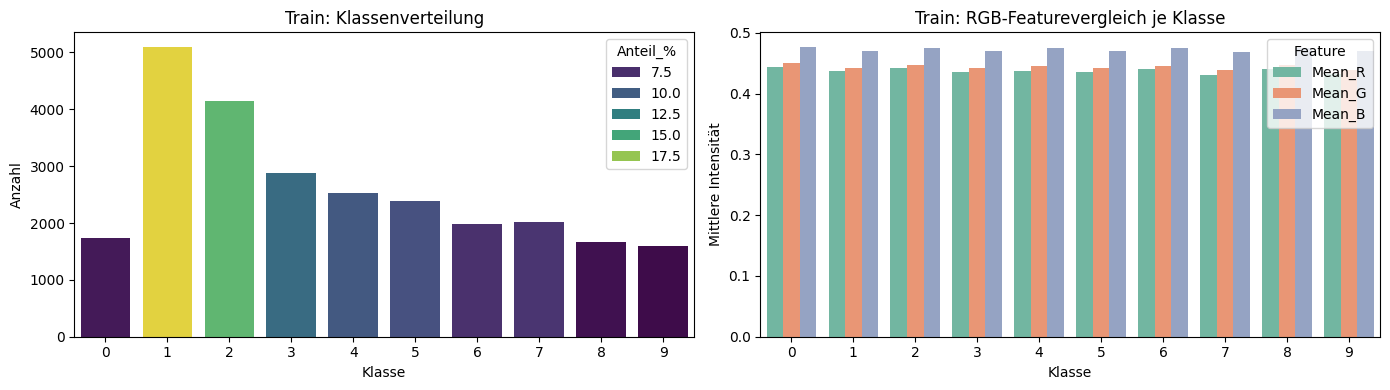

In [8]:
# Featurevergleich (RGB-Intensitäten je Klasse)
def feature_comp(ds, labels, split_name="Train"):
    images = ds.data.astype(np.float32) / 255.0  # (N, C, H, W)

    # Featurevergleich: mittlere RGB-Intensitäten je Bild und Klasse
    mean_r = images[:, 0].mean(axis=(1, 2))
    mean_g = images[:, 1].mean(axis=(1, 2))
    mean_b = images[:, 2].mean(axis=(1, 2))
    mean_intensity = images.mean(axis=(1, 2, 3))

    feat_df = pd.DataFrame({
        "Klasse": labels,
        "Mean_R": mean_r,
        "Mean_G": mean_g,
        "Mean_B": mean_b,
        "Mean_Intensity": mean_intensity
    })

    class_feat = feat_df.groupby("Klasse")[["Mean_R", "Mean_G", "Mean_B", "Mean_Intensity"]].mean()
    print(f"\n=== {split_name}: Durchschnittliche Feature-Werte je Klasse ===")
    print(class_feat.round(4))

    # Visualisierungen
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    dist_df, _ = class_dist(labels)
    sns.barplot(data=dist_df, x="Klasse", y="Anzahl", ax=axes[0], palette="viridis", hue="Anteil_%", dodge=False)
    axes[0].set_title(f"{split_name}: Klassenverteilung")
    axes[0].set_xlabel("Klasse")
    axes[0].set_ylabel("Anzahl")

    class_feat_plot = class_feat.reset_index().melt(
        id_vars="Klasse",
        value_vars=["Mean_R", "Mean_G", "Mean_B"],
        var_name="Feature",
        value_name="Mittelwert"
    )
    sns.barplot(data=class_feat_plot, x="Klasse", y="Mittelwert", hue="Feature", ax=axes[1], palette="Set2",)
    axes[1].set_title(f"{split_name}: RGB-Featurevergleich je Klasse")
    axes[1].set_xlabel("Klasse")
    axes[1].set_ylabel("Mittlere Intensität")
    axes[1].legend(title="Feature")

    plt.tight_layout()
    plt.show()

feature_comp(train_loader.dataset, train_labels, split_name="Train")


=== Test: Durchschnittliche Feature-Werte je Klasse ===
        Mean_R  Mean_G  Mean_B  Mean_Intensity
Klasse                                        
0       0.4579  0.4578  0.4757          0.4638
1       0.4518  0.4501  0.4653          0.4557
2       0.4483  0.4494  0.4664          0.4547
3       0.4475  0.4496  0.4664          0.4545
4       0.4517  0.4528  0.4702          0.4582
5       0.4530  0.4531  0.4695          0.4585
6       0.4591  0.4591  0.4743          0.4641
7       0.4515  0.4519  0.4688          0.4574
8       0.4582  0.4561  0.4724          0.4623
9       0.4553  0.4551  0.4721          0.4609


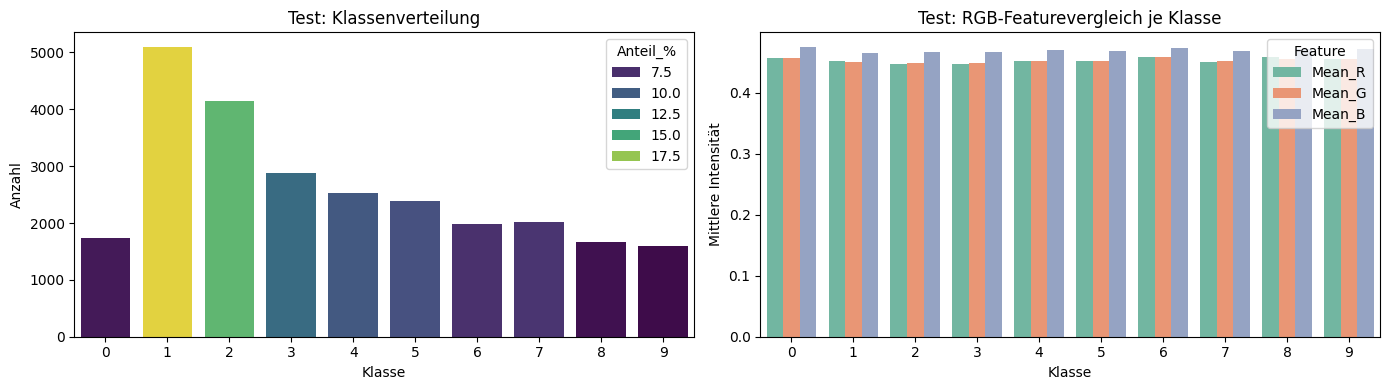

In [9]:
feature_comp(test_loader.dataset, test_labels, split_name="Test")

Sowohl der Trainings- als auch der Testdatensatz weisen eine moderate Klassenimbalance auf. 
Die Daten sind über beide Splits hinweg sehr konsistent verteilt.

Dominante Klasse: Klasse 1 stellt in beiden Datensätzen mit ~19 % den größten Anteil dar.
Unterrepräsentierte Klassen: Die Klassen 0 (Train) und 9 (Test) bilden mit jeweils ~6 % die Schlusslichter.
* **Imbalance-Ratio**: Das Verhältnis zwischen der häufigsten und seltensten Klasse liegt bei 2,98 (Train) bzw. 3,20 (Test).

#### Preprocessing

Um das ML zu erleichtern, werde ich eine Normalisierung vornehmen. Der Mittelwert und die Standardabweichung pro Farbe (Channel) werden auf der Trainingsklasse berechnet und beide Sätze (Training und Test) werden dann mit diesen Zahlen normalisiert. Alternativ wäre es möglich, die bewährten Standardwerte von Imagenet zu verwenden.

In [10]:
# Preprocessing der Daten
# calculate mean and std for normalization for each channel
def get_stats(loader):
    sum_, squared_sum, batches = 0, 0, 0
    
    for images, _ in loader:
        # images: [batch_size, 3, 32, 32]
        sum_ += torch.mean(images, dim=[0, 2, 3])
        squared_sum += torch.mean(images**2, dim=[0, 2, 3])
        batches += 1
        
    mean = sum_ / batches
    std = (squared_sum / batches - mean**2)**0.5
    return mean, std

# Berechnung
mean, std = get_stats(train_loader)
print(f"Mean: {mean}")
print(f"Std: {std}")


Mean: tensor([0.4377, 0.4438, 0.4728])
Std: tensor([0.1980, 0.2010, 0.1970])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8734728..0.1919533].


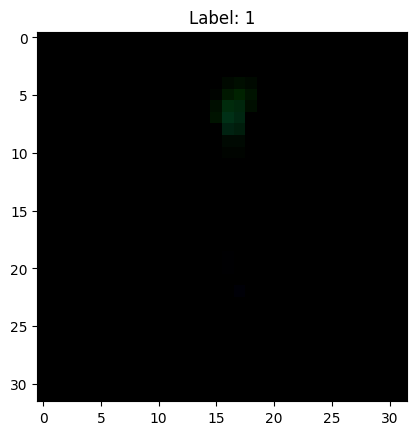

In [11]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

train_set = datasets.SVHN(root='../data', split='train', download=True, transform=transform)
test_set = datasets.SVHN(root='../data', split='test', download=True, transform=transform)
    
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

# 2. Visualisieren
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Normalisiertes Bild Anzeigen:
plt.imshow(images[0].permute(1, 2, 0)) # Permute für (H, W, C)
plt.title(f"Label: {labels[0]}")
plt.show()

### 2. Evaluation

* Lege die Metriken fest, mit denen die Performance der Modelle gemessen werden soll (z. B. Accuracy, F1-Score, Loss).



#### Metriken

Da der vorliegende Datensatz eine leichte Klassenimbalance aufweist, ist die Accuracy als alleinige Metrik nicht aussagekräftig und könnte leicht verzerrt sein.   
Um die Modellleistung über alle Kategorien hinweg objektiv zu bewerten, konzentriere ich mich stattdessen auf den F1-Score sowie auf Precision und Recall. All diese Metriken (inklusive Accuracy) werden auf Wandb geloggt. Da es sich um ein Multiclass-Problem handelt, werde ich als Beurteilungsmetrik vor allem den Macro-Average F1-Score verwenden.

Für eine Klasse C wird der Macro-F1-Score wie folgt berechnet:

$$
    \text{Precision}_{c}=\frac{\text{True\ Positives}_{c}}{\text{True\ Positives}_{c}+\text{False\ Positives}_{c}}
$$
$$
    \text{Recall}_{c}=\frac{\text{True\ Positives}_{c}}{\text{True\ Positives}_{c}+\text{False\ Negatives}_{c}}
$$
$$
\text{F1}_{c}=2\times \frac{\text{Precision}_{c}\times \text{Recall}_{c}}{\text{Precision}_{c}+\text{Recall}_{c}}
$$.  
$$
\text{Macro\ F1}=\frac{1}{N}\sum _{c=1}^{N}\text{F1}_{c}
$$

Dadurch werden die Minderheitsklassen angemessen berücksichtigt. Es wird verhindert, dass das Modell allein durch das Weglassen kleinerer Klassen einen hohen Wert erreicht.

#### Loss
Neben klassischen Klassifikationsmetriken wird der Cross-Entropy Loss direkt als Evaluationsmetrik genutzt. Falls das Modell bei den seltenen Klassen trotz guter Gesamt-Accuracy unsicher ist, spiegelt sich das sofort in einem erhöhten CE-Loss wider. 

### 3. Implementierung der Basisfunktionalität

a) Training & Evaluation: Erstelle Funktionen oder Klassen für den standardisierten Trainings- und Evaluationsprozess.

b) MLOps Integration: Binde eine Plattform wie Weights & Biases (W&B) ein, um Experimente zu loggen.

c) Basismodell: Implementiere das vereinbarte einfache Basismodell.

d) Overfitting Test: Trainiere das Modell mit einem einzelnen Sample oder einem einzigen Batch. Wenn das Modell verlustfrei auf diesem Batch lernt, ist die Basisfunktionalität korrekt implementiert.


#### Design

1. **Konfiguration über `RunConfig`**
    - Zentrale Parameter (z. B. `learning_rate`, `batch_size`, `epochs`, `device`) werden in `baseline_config` gebündelt.

2. **Baseline-Training über `run_baseline(...)`**

3. **Experiment-Tracking mit Weights & Biases**
    - Aktiviert über `use_wandb=True` in der Config.
    - Projektname: `DEL`, Run-Name: `baseline-example`.

4. **Auswertung über `WandbRuns`**
    - lädt Runs aus W&B:
    ```python
    wandb_runs = WandbRuns(project="DEL")
    overview_df = wandb_runs.runs_overview(top_k=10)
    ```
    - Zusätzlich vergleichst du Metriken (z. B. `val/loss`) direkt zwischen Runs.


#### Struktur

```text
src/
├── hyp_tests
│   ├── results
│   │   └── ...csv / json
│   ├── Baseline.py
│   ├── Hypothese_01...10.py
│   └── run_all.py
├── training.py
│   ├── RunConfig           # Konfigurationsdataclass für Training
│   └── run_baseline(...)   # Führt Baseline-Training + Evaluation aus
├── wandb_tools.py
│   └── WandbRuns           # Laden, Filtern, Vergleichen von W&B-Runs
├── model.py                # Modellarchitekturen
├── metrics.py              # F1, Precision, Recall (Macro)
└── cross_validation.py 
```

#### 3d) Overfitting-Test

In [30]:

# single batch aus dem train_loader extrahieren
batch_images, batch_labels = next(iter(train_loader))
overfit_dataset = TensorDataset(batch_images.clone(), batch_labels.clone())
overfit_loader = DataLoader(overfit_dataset, batch_size=len(overfit_dataset), shuffle=False)

target_epochs = 1000

overfit_config = RunConfig(
    learning_rate=1e-2,
    batch_size=len(overfit_dataset),
    epochs=target_epochs,
    use_wandb=False,
    wandb_project="DEL",
    run_name="overfit-single-batch",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_seed=42,
    tags=["overfit-check"],
    gradient_clipping=False,
)

overfit_result = run_baseline(
    config=overfit_config,
    fit_config=FitConfig(epochs=target_epochs),
    train_loader=overfit_loader,
)


In [31]:
history = overfit_result["history"]
print(f"Final train accuracy: {history['train_accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history['val_accuracy'][-1]:.4f}")
print(f"Final train loss: {history['train_loss'][-1]:.4f}")
print(f"Final val loss: {history['val_loss'][-1]:.4f}")

Final train accuracy: 1.0000
Final val accuracy: 0.1667
Final train loss: 0.0014
Final val loss: 11.3933


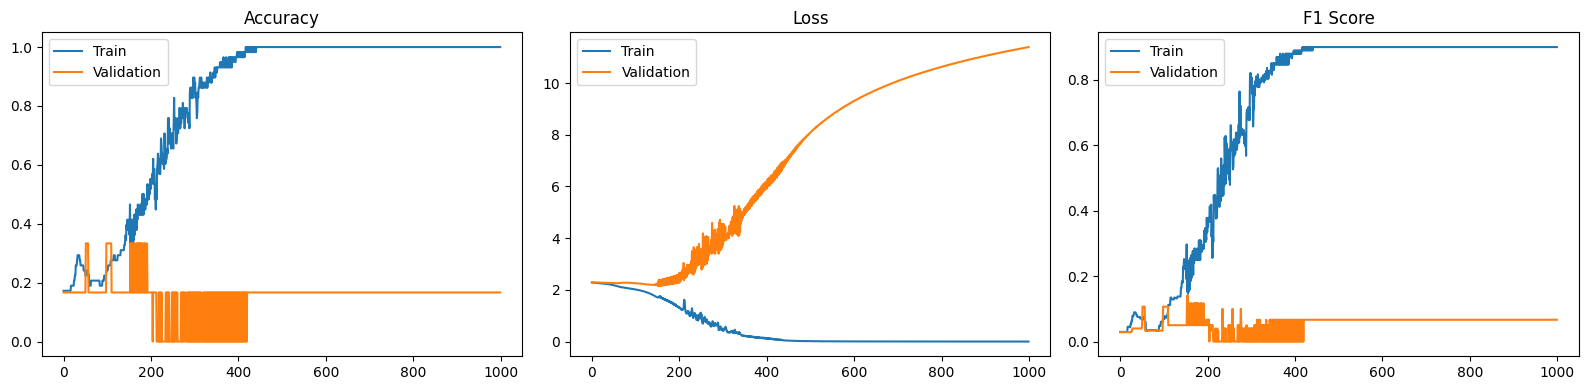

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(pd.DataFrame(history["train_accuracy"]))
axes[0].plot(pd.DataFrame(history["val_accuracy"]))
axes[0].set_title("Accuracy")
axes[0].legend(["Train", "Validation"])

axes[1].plot(pd.DataFrame(history["train_loss"]))
axes[1].plot(pd.DataFrame(history["val_loss"]))
axes[1].set_title("Loss")
axes[1].legend(["Train", "Validation"])

axes[2].plot(pd.DataFrame(history["train_macro_f1"]))
axes[2].plot(pd.DataFrame(history["val_macro_f1"]))
axes[2].set_title("F1 Score")
axes[2].legend(["Train", "Validation"])

plt.tight_layout()
plt.show(fig)

Das Modell scheint sehr gut auf einen einzelnen Batch zu übertrainieren. Während der Trainingsloss gegen 0 konvergiert, scheint der Validierungsloss zu divergieren. Dies zeigt, dass unser Modell die Daten perfekt auswendig lernen kann, wenn genügend Zeit gegeben ist. Dies impliziert, dass zumindest die Basisfunktionalität korrekt implementiert wurde und das Modell lernfähig ist. Die Genauigkeit und der F1-Score sind bei den Trainings auf dem Maximum, im Validierungslauf jedoch nicht ganz auf 0.  
Das liegt daran, dass auch bei vollkommen willkürlichen Vermutungen in 10 Klassen (wobei die tieferen Klassen wahrscheinlicher sind als die höheren) eine Genauigkeit von ungefähr 0,166 erreicht werden kann. Dies ist bei einem perfekten Overfit zu erwarten.

### 4. Training des Basismodells

In diesem Abschnitt wird die geforderte Basis-Konfiguration umgesetzt:
- SGD ohne Momentum
- keine Regularisierung (weight decay = 0)
- keine Batch-Normalization
- manuelles Tuning von Lernrate und Batchsize (kein Auto-Search)
- Schätzung des statistischen Fehlers mit Cross-Validation

#### 4a) Training mit SGD ohne Momentum/Regularisierung/BatchNorm (alle Trainingsdaten)

Es wird auf dem gesamten Trainingsset trainiert. Zur Lernkurven-Überwachung dient das ein separiertes Validation-Dataset (0.1) als Evaluationsset pro Epoche.

In [15]:
baseline_config = RunConfig(
    learning_rate=1e-2,
    batch_size=64,
    epochs=30,
    use_wandb=True,
    val_fraction=0.1,
    wandb_project="DEL",
    run_name="Baseline-Example",
    tags=["baseline"],
    device=DEVICE,
    random_seed=SEED,
    num_workers=4,
    pin_memory=torch.cuda.is_available(),
    gradient_clipping=False,
)
 
baseline_result = run_baseline(
    config=baseline_config,
    fit_config=FitConfig(epochs=baseline_config.epochs),
    train_loader=train_loader,
)

wandb: Currently logged in as: lukas-breiter (lukas-breiter-fachhochschule-nordwestschweiz-fhnw) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


epoch,▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇███
train/accuracy,▁▂▆▇▇▇▇▇▇█████████████████████
train/loss,█▇▄▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/macro_f1,▁▂▆▇▇▇▇▇██████████████████████
train/macro_precision,▁▄▆▇▇▇▇▇██████████████████████
train/macro_recall,▁▂▆▇▇▇▇▇▇█████████████████████
val/accuracy,▁▃▅▇▇█████████▇███████████████
val/loss,█▇▄▂▂▁▁▁▁▁▁▁▁▁▃▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂
val/macro_f1,▁▄▆▇▇█████████▇███████████████
val/macro_precision,▁▆██▇█████████████████████████
+1,...


In [16]:
Baseline_firstRun = list(
    api.runs(
        path=project_path,
        filters={
            "config.run_name": "Baseline-Example",
        },
    )
)

baseline_example_hist = Baseline_firstRun[0].history(
    keys=["val/macro_recall", "val/macro_precision", "val/macro_f1", "val/loss", "val/accuracy", "train/accuracy", "train/loss", "train/macro_recall", "train/macro_precision", "train/macro_f1"],
)

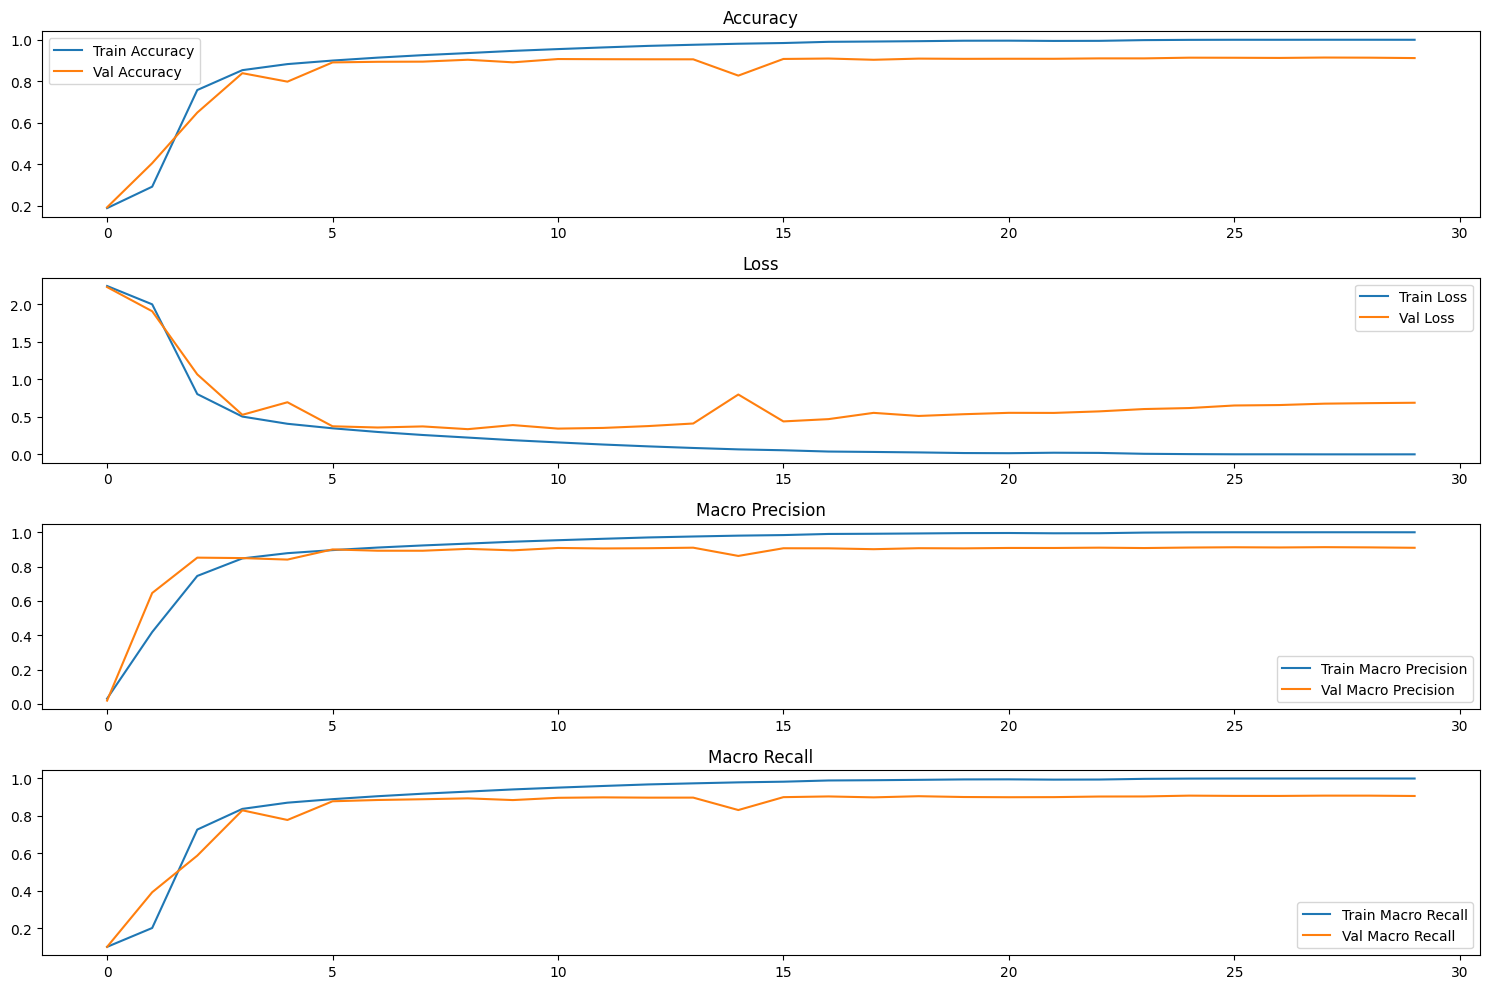

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(15, 10))
axes[0].plot(baseline_example_hist["train/accuracy"], label="Train Accuracy")
axes[0].plot(baseline_example_hist["val/accuracy"], label="Val Accuracy")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(baseline_example_hist["train/loss"], label="Train Loss")
axes[1].plot(baseline_example_hist["val/loss"], label="Val Loss")
axes[1].set_title("Loss")
axes[1].legend()

axes[2].plot(baseline_example_hist["train/macro_precision"], label="Train Macro Precision")
axes[2].plot(baseline_example_hist["val/macro_precision"], label="Val Macro Precision")
axes[2].set_title("Macro Precision")
axes[2].legend()

axes[3].plot(baseline_example_hist["train/macro_recall"], label="Train Macro Recall")
axes[3].plot(baseline_example_hist["val/macro_recall"], label="Val Macro Recall")
axes[3].set_title("Macro Recall")
axes[3].legend()

plt.tight_layout()
plt.show()


Wir können feststellen, dass das Modell über die 30 Epochen hinweg eine stetige Verbesserung der Trainings- und Validierungsgenauigkeit aufzeigt, was auf erfolgreiches Lernen hindeutet. 
Die Verlustkurven zeigen zu Beginn einen Abwärtstrend, was positiv ist. Allerdings scheint sich der Validierungsverlust ab der 10. Epoche zu erhöhen, allerdings bleibt der Macro F1-Score weiterhin stabil.  
Dies kann passieren, wenn sich die kontinuierliche Verlustfunktion und die diskrete Metrik des Macro-F1-Scores entkoppeln. Während der ansteigende Validierungsverlust darauf hindeutet, dass das Modell bei seinen Vorhersagen unsicherer wird oder seine Fehler überbewertet (Verschlechterung der probabilistischen Kalibrierung), bleibt die harte Klassifikationsgrenze stabil. Solange der F1-Score marginal steigt, optimiert das Modell seine Trennschärfe für Grenzfälle und lernt trotz beginnendem Overfitting sinnvolle Muster. 
Da der F1-Score hier die primäre Evaluationsmetrik darstellt, ist diese Divergenz unbedenklich.

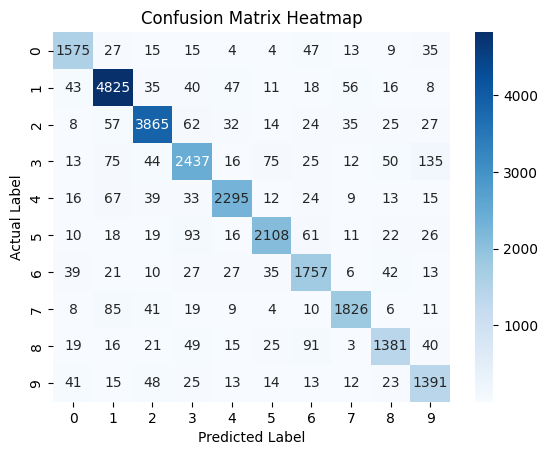

In [18]:
model = baseline_result["model"].to("cuda")

for module in model.modules():
    module._forward_hooks.clear()
    module._forward_pre_hooks.clear()
    module._backward_hooks.clear()

model.eval()

# Listen zum Sammeln aller Ergebnisse über das gesamte Testset
all_predictions = []
all_labels = []
all_probabilities = []

# 2. Schleife über den gesamten Test-Loader (alle Batches)
with torch.no_grad():  # Deaktiviert die Gradientenberechnung für alle Batches
    for images, labels in test_loader:
        # Daten auf die GPU/CPU schieben
        images = images.to(DEVICE)
        
        # Forward Pass
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(probabilities, dim=1)
        
        # Ergebnisse zurück auf die CPU verschieben und speichern
        all_predictions.append(predictions.cpu())
        all_labels.append(labels)  # labels sind meistens schon auf der CPU, falls nicht: labels.cpu()
        all_probabilities.append(probabilities.cpu())

# 3. Alle Batches zu einem einzigen grossen Tensor zusammenfügen (konkatenieren)
all_predictions = torch.cat(all_predictions, dim=0)
all_labels = torch.cat(all_labels, dim=0)
all_probabilities = torch.cat(all_probabilities, dim=0)

cm = confusion_matrix(all_labels, all_predictions)

# 2. Plot the heatmap
class_labels = list(range(10))  # digits 0-9
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

# 3. Add formatting labels
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix Heatmap')
plt.show()



Die Confusion Matrix des einfachen Basismodells auf den Testdaten zeigt, dass die meisten Klassen gut erkannt werden. Es gibt jedoch einige Verwechslungen, insbesondere zwischen den Klassen 1 und 4 sowie 3 und 9, die allerdings sehr selten sind (maximal 200). Unser Modell lernt also nicht nur die Mehrheitsklasse aus und es findet auch kein nennenswertes Overfitting auf den Trainingsdaten statt.   

In [19]:
print("Finale Werte (4a):")
baseline_example_hist = baseline_example_hist.sort_values("_step")
print(f"val_loss: {baseline_example_hist['val/loss'].iloc[-1]:.4f}")
print(f"val_accuracy: {baseline_example_hist['val/accuracy'].iloc[-1]:.4f}")
print(f"val_macro_precision: {baseline_example_hist['val/macro_precision'].iloc[-1]:.4f}")
print(f"val_macro_recall: {baseline_example_hist['val/macro_recall'].iloc[-1]:.4f}")
print(f"val_macro_f1: {baseline_example_hist['val/macro_f1'].iloc[-1]:.4f}")

Finale Werte (4a):
val_loss: 0.6888
val_accuracy: 0.9117
val_macro_precision: 0.9094
val_macro_recall: 0.9065
val_macro_f1: 0.9078


Es fällt auf, dass das Modell anscheinend schon ohne genauere Konfiguration recht gut zu performen scheint (Makro F1 von 0,9079). Ein derart hoher Einstiegswert im unkonfigurierten Zustand deutet darauf hin, dass die gewählte Modellarchitektur sehr gut mit der zugrunde liegenden Datenstruktur korreliert oder / und die Repräsentationen im Merkmalsraum von Natur aus eine hohe Separierbarkeit aufweisen. Dies schafft eine solide und verlässliche Basis für darauf aufbauende Optimierungsschritte.

#### 4b) Manuelles Tuning von Lernrate und Batchsize (keine automatische Suche)

Für das Tuning wird ausschließlich die etablierte Funktion `run_baseline(...)` aus `src.training` verwendet.
Es wird ein kleiner manueller Grid getestet (kein Bayes, kein AutoML).

In [ ]:
learning_rates = [1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1]
batch_sizes = [32, 64, 128, 256, 512]
tuning_epochs =  30

for lr, bs in tqdm(itertools.product(learning_rates, batch_sizes), desc="Tuning"):
    run_name = f"Baseline_Tuning-lr{lr}-bs{bs}"
    train_loader_cfg,_ = load_svhn_data(batch_size=bs)

    result = run_baseline(
        config=RunConfig(
            learning_rate=lr,
            batch_size=bs,
            epochs=tuning_epochs,
            val_fraction=0.1,
            use_wandb=True,
            wandb_project="DEL",
            run_name=run_name,
            tags=["baseline", "Baseline-Tuning"],
            device=DEVICE,
            random_seed=SEED,
            num_workers=4,
            pin_memory=torch.cuda.is_available(),
            gradient_clipping=False,
            silent=True,
        ),
        fit_config=FitConfig(epochs=tuning_epochs),
        train_loader=train_loader_cfg,
        extra_wandb_config={
            "experiment_name": "Baseline-Tuning",
        },
    )

Tuning: 36it [1:17:34, 129.30s/it]


In [60]:
baseline_tuning_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name.value": "Baseline-Tuning",
        },
    )
)

In [61]:
tuning_results = []

for Baseline_tuning_run in baseline_tuning_wandb_runs:
    baseline_tuning = Baseline_tuning_run.history(
        keys=["val/macro_recall", "val/macro_precision", "val/macro_f1", "val/loss", "val/accuracy", 
              "train/accuracy", "train/loss", "train/macro_recall", "train/macro_precision", "train/macro_f1"
              ],
    )

    hist_df = baseline_tuning.copy()

    hist_df["run_id"] = Baseline_tuning_run.id
    hist_df["learning_rate"] = Baseline_tuning_run.config.get("learning_rate")
    hist_df["batch_size"] = Baseline_tuning_run.config.get("batch_size")
    
    tuning_results.append(hist_df)

tuning_result_df = pd.concat(tuning_results, ignore_index=True)

In [62]:
# Build one-row-per-run summary from tuning_result_df (last logged epoch per run)
tuning_df = (
    tuning_result_df
    .sort_values(["run_id", "_step"])
    .groupby("run_id", as_index=False)
    .tail(1)
    .loc[:, [
        "run_id",
        "learning_rate",
        "batch_size",
        "val/loss",
        "val/accuracy",
        "val/macro_precision",
        "val/macro_recall",
        "val/macro_f1"
    ]]
    .rename(columns={
        "val/loss": "val_loss",
        "val/accuracy": "val_accuracy",
        "val/macro_precision": "val_macro_precision",
        "val/macro_recall": "val_macro_recall",
        "val/macro_f1": "val_macro_f1",
    })
    .copy()
)

tuning_df[["learning_rate", "batch_size", "val_macro_f1","val_loss", "val_accuracy", "val_macro_precision", "val_macro_recall"]].sort_values("val_macro_f1", ascending=False)

,learning_rate,batch_size,val_macro_f1,val_loss,val_accuracy,val_macro_precision,val_macro_recall
779,0.100,64,0.921598,0.660893,0.925734,0.924864,0.919020
869,0.100,128,0.919947,0.732739,0.924915,0.922885,0.917442
599,0.050,64,0.919645,0.714601,0.924369,0.922355,0.917276
569,0.050,32,0.916306,0.681836,0.921911,0.919634,0.913754
689,0.050,128,0.911533,0.721481,0.916177,0.913818,0.909614
839,0.100,256,0.910049,0.726614,0.915495,0.912923,0.907532
659,0.050,256,0.909725,0.590942,0.915768,0.912685,0.907060
389,0.010,32,0.905535,0.672257,0.910853,0.909452,0.902206
719,0.050,512,0.896701,0.390302,0.900887,0.902160,0.892974
419,0.010,64,0.895376,0.5417,0.900341,0.897844,0.894167


In [63]:
best_cfg_F1 = tuning_df.sort_values("val_macro_f1", ascending=False).iloc[0]
best_lr = (best_cfg_F1["learning_rate"])
best_bs = (best_cfg_F1["batch_size"])
print(f"Beste Konfiguration nach val_macro_f1: lr={best_lr}, batch_size={best_bs}")
print(f"Best val_macro_f1 score: {best_cfg_F1.val_macro_f1}")

Beste Konfiguration nach val_macro_f1: lr=0.1, batch_size=64
Best val_macro_f1 score: 0.921597578985691


In [64]:
# Convert val/loss to numeric, coercing errors to NaN
tuning_result_df["val/loss"] = pd.to_numeric(tuning_result_df["val/loss"], errors='coerce')

# Now find the best configuration
best_row_loss = tuning_result_df.loc[tuning_result_df['val/loss'].idxmin()]


best_lr_loss = best_row_loss['learning_rate']
best_bs_loss = best_row_loss['batch_size']
best_step_loss = best_row_loss['_step']
best_f1_loss = best_row_loss['val/macro_f1']

print(f"Beste Konfiguration nach val_loss: lr={best_lr_loss}, batch_size={best_bs_loss} at step {int(best_step_loss)}")
print(f"Best val_loss score: {best_row_loss['val/loss']:.6f}")
print(f"Best val_macro_f1 score: {best_f1_loss:.6f}")

Beste Konfiguration nach val_loss: lr=0.05, batch_size=32 at step 6
Best val_loss score: 0.294049
Best val_macro_f1 score: 0.912398


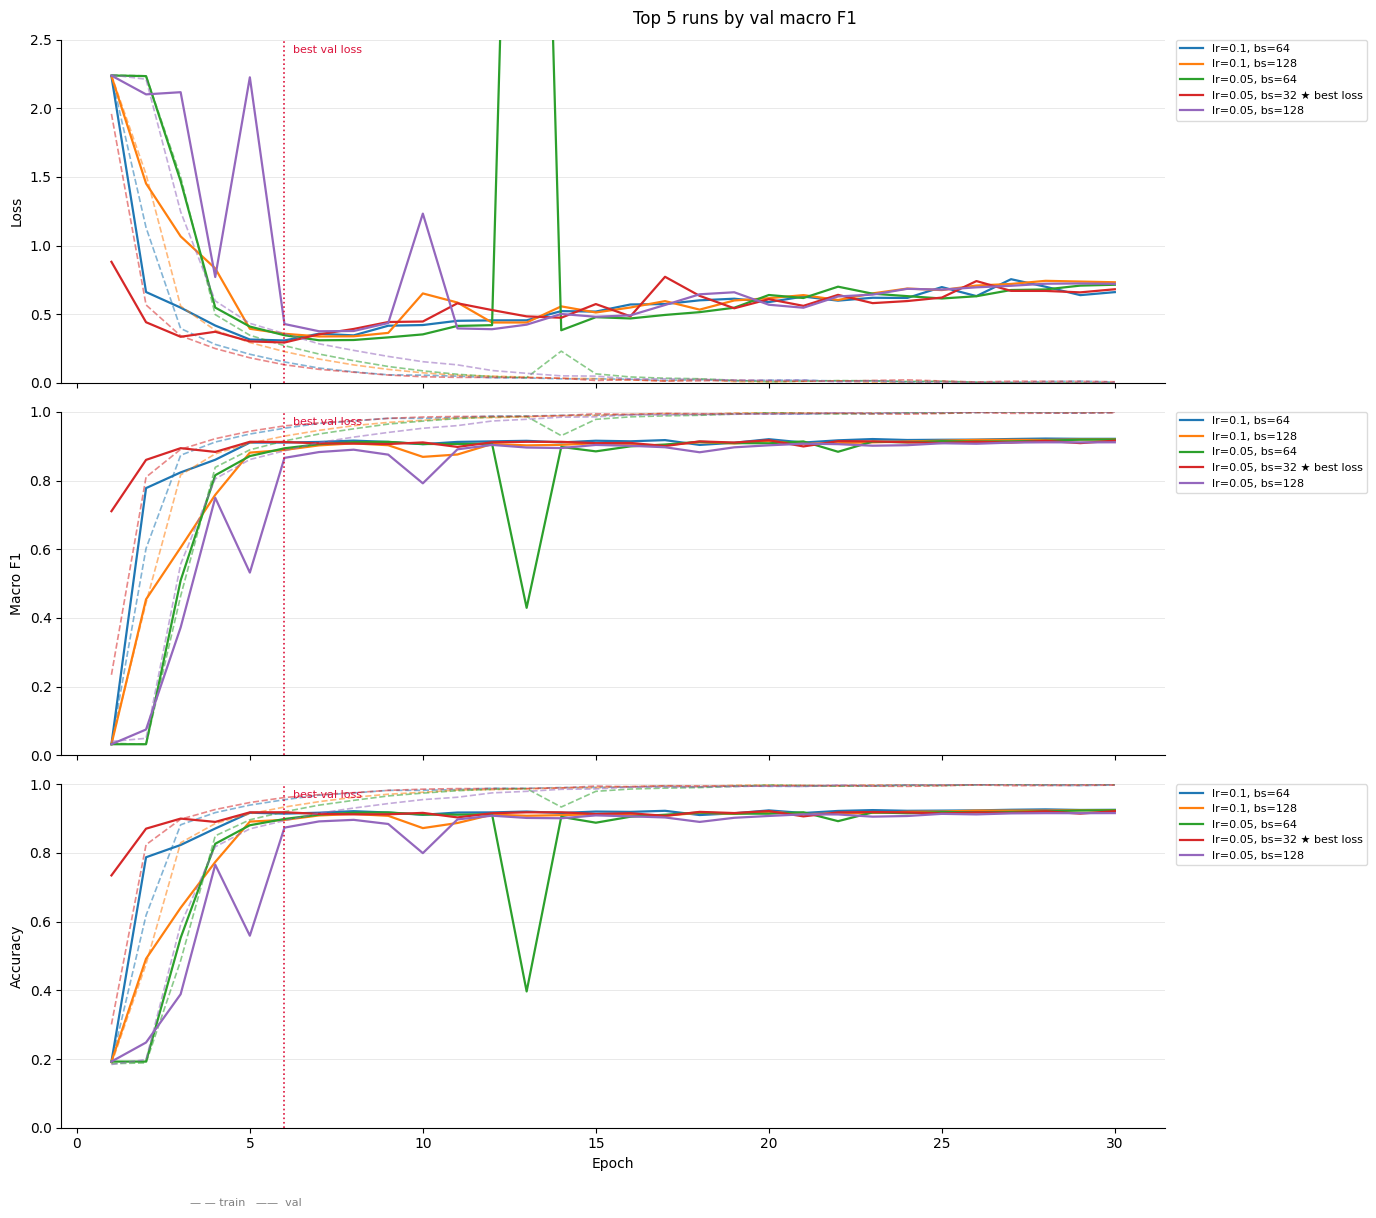

In [ ]:
#  data prep 
top_run_ids = tuning_df.sort_values("val_macro_f1", ascending=False)["run_id"].head(5).tolist()
best_loss_run = best_row_loss["run_id"]
best_f1_run = best_cfg_F1["run_id"]

if best_loss_run not in top_run_ids:
    top_run_ids.append(best_loss_run)

METRICS = [
    ("val/loss",      "Loss",     None,   (0, 2.5)),
    ("val/macro_f1",  "Macro F1", None,   (0, 1)),
    ("val/accuracy",  "Accuracy", None,   (0, 1)),
]

#  plot 
fig, axes = plt.subplots(len(METRICS), 1, figsize=(15, 4 * len(METRICS)), sharex=True)
fig.suptitle("Top 5 runs by val macro F1")

prop_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for ax, (metric_key, ylabel, _, ylim) in zip(axes, METRICS):
    ax.set_ylabel(ylabel)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", linewidth=0.4, alpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)

    for i, run_id in enumerate(top_run_ids):
        df_run = (
            tuning_result_df[tuning_result_df["run_id"] == run_id]
            .sort_values("_step")
        )
        if df_run.empty or metric_key not in df_run.columns:
            continue

        lr  = df_run["learning_rate"].iloc[0]
        bs  = df_run["batch_size"].iloc[0]

        col = prop_cycle[i % len(prop_cycle)]
        is_best = (run_id == best_loss_run)
        is_best_f1 = (run_id == best_f1_run)
        lw_val  = 1.6
        label   = f"lr={lr}, bs={bs}" + (" ★ best loss" if is_best else "* best F1" if is_best_f1 else "")

        ax.plot(df_run["_step"], df_run[metric_key],
                color=col, linewidth=lw_val, label=label)

        train_key = metric_key.replace("val/", "train/")
        if train_key in df_run.columns:
            ax.plot(df_run["_step"], df_run[train_key],
                    color=col, linewidth=1.2, linestyle="--", alpha=0.55)

    ax.axvline(best_row_loss["_step"], color="crimson",
               linewidth=1.2, linestyle=":", zorder=5)
    ax.annotate(
        "best val loss",
        xy=(best_row_loss["_step"], ax.get_ylim()[1]),
        xytext=(6, -4), textcoords="offset points",
        color="crimson", fontsize=8, va="top",
    )

    # Legend outside to the right
    ax.legend(fontsize=8, framealpha=0.7,
              loc="upper left", bbox_to_anchor=(1.01, 1),
              borderaxespad=0)

axes[-1].set_xlabel("Epoch")

fig.text(0.13, -0.01, "— — train   ——  val", fontsize=8, color="gray", va="top")

plt.tight_layout()
plt.subplots_adjust(right=0.78)

plt.show()

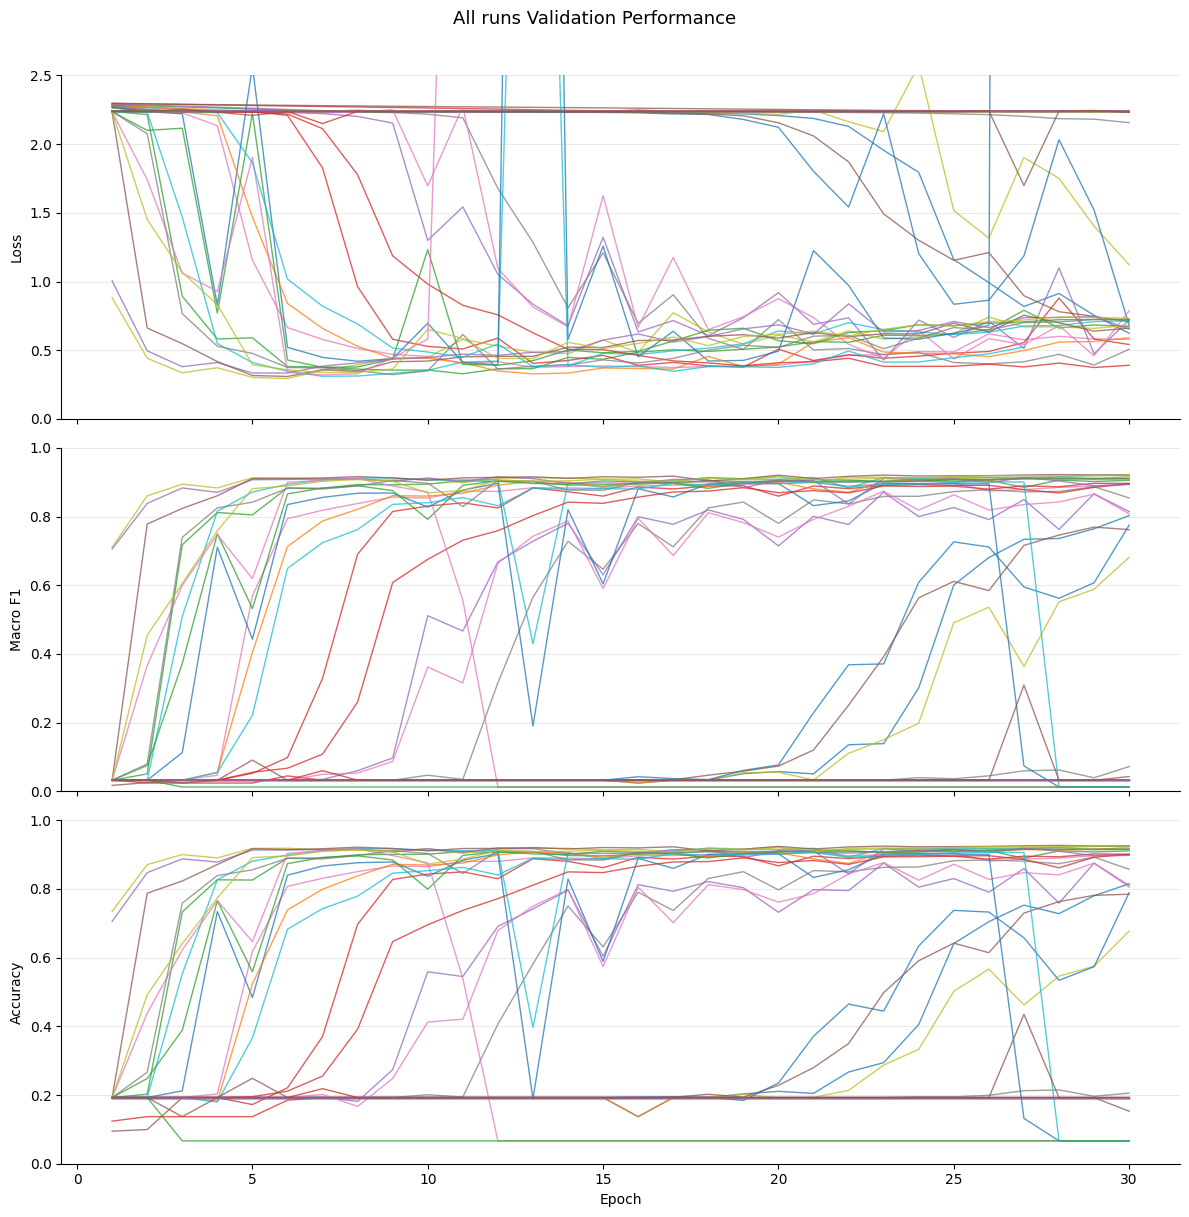

In [15]:
all_run_ids = tuning_result_df["run_id"].unique()

METRICS = [
    ("val/loss",     "Loss",     (0, 2.5)),
    ("val/macro_f1", "Macro F1", (0, 1)),
    ("val/accuracy", "Accuracy", (0, 1)),
]

fig, axes = plt.subplots(len(METRICS), 1, figsize=(12, 4 * len(METRICS)), sharex=True)
fig.suptitle("All runs Validation Performance", fontsize=13, y=1.01)

prop_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for ax, (metric_key, ylabel, ylim) in zip(axes, METRICS):
    ax.set_ylabel(ylabel)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", linewidth=0.4, alpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)

    for i, run_id in enumerate(all_run_ids):
        df_run = (
            tuning_result_df[tuning_result_df["run_id"] == run_id]
            .sort_values("_step")
        )
        if df_run.empty or metric_key not in df_run.columns:
            continue

        col = prop_cycle[i % len(prop_cycle)]


        ax.plot(df_run["_step"], df_run[metric_key],
                color=col, alpha=0.75, linewidth=1.0)


axes[-1].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

##### Interpretation:
- Zu grosse Lernraten können zu Oszillation oder Divergenz führen
- Zu kleine Lernraten konvergieren stabiler, benötigen aber viel mehr Epochen (alle linienen mit tiefer lernrate). Sie könnten in lokalen Minima stecken bleiben.
- Theoretisch: Kleinere Batches erzeugen noisigere Gradienten und können besser generalisieren,  sind rechenintensiver (über doppelt so lange).

Bei 30 Epochen sind die besten Gesamtkonfigurationen eine Lernrate von 0,1 und eine Batchgröße von 64. Damit wurden die höchste Validierungsgenauigkeit (0,913) sowie der stärkste Makro-F1-Wert (0,0.918) erzielt. Ein solcher Makro-F1-Score deutet darauf hin, dass das Modell nicht nur insgesamt, sondern auch über alle Klassen hinweg relativ ausgewogen gute Ergebnisse liefert.

Ein klares Muster ist, dass grössere Batch-Grössen nur in Kombination mit einer hohen Lernrate gut funktionieren. So schnitt die Batchgröße 128 bei einer Lernrate von 0,05 gut ab, bei 0,01 jedoch deutlich schlechter und insbesondere bei 0,005, wo die Leistung stark abfiel. Dies deutet darauf hin, dass die niedrigeren Lernraten bei 30 Epochen weiterhin schwächer waren, insbesondere bei großen Batches.

Die Flachen lininen im Plot sind alle Modelle mit einer zu tiefen Lernrate. Das Model fängt hier gar nicht erst an Wirklich zu lernen, sondern bleibt in einem sehrschlechten, lokalen Minima stecken, da die schrittgrösse nicht gross genug is um daraus "herauszsteigen".


Bei kleineren Batchgrössen von 32 und 64 sind die Ergebnisse stabiler. Die meisten Durchläufe erreichten eine Genauigkeit von etwa 0,90 bzw. 0,89–0,92 bei Makro-Präzision/Recall/F1. Dies deutet darauf hin, dass das Modell in diesem Bereich im Allgemeinen robust ist.


Auch erkennen wir mindestens ein Modell, bei dem das zuvor genannte Problem des Exploding Gradients auftritt. Es liefert keine brauchbaren Resultate mehr und „schmiert ab”. Genau das soll durch das spätere Gradient Clipping vermieden werden, da dies das Training hoffentlich stabilisieren wird.


#### 4c) Schätzung des statistischen Fehlers mit Cross-Validation

Die Fold-Splits werden mit `kfold_indices(...)` aus `src.cross_validation` erzeugt.
Trainiert wird pro Fold mit `Trainer` aus `src.training` bei identischem Basismodell und SGD-Setup.

In [35]:
X = train_set.data.astype(np.float32)

if X.ndim == 4 and X.shape[1] == 3:
    pass
elif X.ndim == 4 and X.shape[-1] == 3:
    X = X.transpose(0, 3, 1, 2)
else:
    raise ValueError(f"Unexpected SVHN data shape: {X.shape}")

X = X / 255.0
X = (X - mean.numpy()[None, :, None, None]) / std.numpy()[None, :, None, None]
y = train_labels.astype(np.int64)


In [ ]:
net = NeuralNetClassifier(
    BaselineCNN,
    max_epochs=30,
    module__num_classes=10,
    lr=best_lr,
    batch_size=int(best_bs),
    optimizer=optim.SGD,
    optimizer__momentum=0.0,
    optimizer__weight_decay=0.0,
    criterion=torch.nn.CrossEntropyLoss,
    device=DEVICE,
    train_split=None,
    verbose=0,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "f1_macro", "precision_macro", "recall_macro"]

results = cross_validate(
    net, X, y, 
    cv=cv, 
    scoring=scoring, 
    n_jobs=-1, 
    return_train_score=True,

)

cv_summary = pd.DataFrame({
    "metric": ["accuracy", "f1_macro", "precision_macro", "recall_macro"],
    "mean": [results[f"test_{m}"].mean() for m in scoring],
    "std": [results[f"test_{m}"].std() for m in scoring],
    "se": [results[f"test_{m}"].std() / np.sqrt(cv.get_n_splits()) for m in scoring],
})

display(cv_summary)


/home/lukas/src/FHNW/del_mc/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lukas/src/FHNW/del_mc/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/lukas/src/FHNW/del_mc/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

,metric,mean,std,se
0,accuracy,0.238043,0.340981,0.152491
1,f1_macro,0.193217,0.361123,0.161499
2,precision_macro,0.188863,0.364216,0.162882
3,recall_macro,0.262744,0.325488,0.145563


In [33]:
#Vizualize 
def visualize_cv_performance(cv_summary, title="Cross-Validation Performance"):
	figure = plt.figure(figsize=(10, 6))
	ax = sns.barplot(data=cv_summary, x="metric", y="mean", palette="Set2", hue="metric", errorbar=None)

	ax.errorbar(
		x=np.arange(len(cv_summary)),
		y=cv_summary["mean"],
		yerr=cv_summary["se"],
		fmt="none",
		ecolor="black",
		capsize=4,
	)

	plt.title(title)
	plt.ylim(0, 1)

	return figure


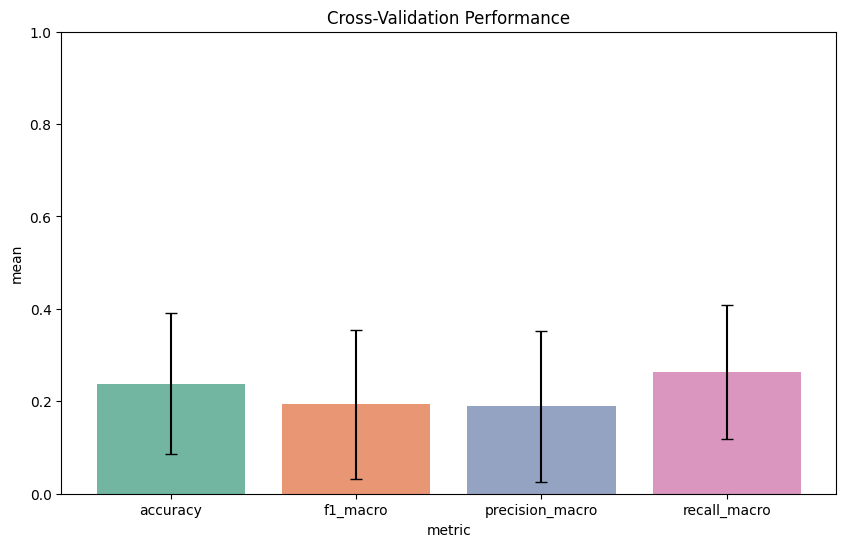

In [ ]:
visualize_cv_performance(cv_summary, title="Cross-Validation Performance").show()

In der obigen Grafik erkennen wir, dass das Modell ziemlich schlecht ist. Dies liegt höchstwahrscheinlich daran, dass diese Konfiguration an Parametern sehr instabil ist. Vermutlich schmieren diese, wie zuvor erwähnt, aufgrund der hohen Lernrate einige der Modelle in dem Sinne ab, dass sie durch exploding gradients keine zuverlässigen Resultate mehr liefern.

Es gibt mehrere Ansätze, wie man dieses Problem bewältigen kann. Ich habe mich später für das Baseline Gradient Clipping sowie die bewährten Standardparameter (Lernrate von 0,01 und eine Batch-Size von 64) entschieden. Andere Lösungsansätze, wie z. B. Architekturoptimierung, Einführung einer Batchnorm oder einen anderen Optimizer, habe ich bewusst nicht implementiert, da dies später in den Hypothesen getestet werden soll.

In [36]:
net_stable = NeuralNetClassifier(
    BaselineCNN,
    max_epochs=30,
    module__num_classes=10,
    lr=1e-2,
    batch_size=64,
    optimizer=optim.SGD,
    optimizer__momentum=0.0,
    optimizer__weight_decay=0.0,
    criterion=torch.nn.CrossEntropyLoss,
    device=DEVICE,
    train_split=None,
    verbose=0,
)

cv_stable = StratifiedKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=SEED
    )
scoring = ["accuracy", "f1_macro", "precision_macro", "recall_macro"]

results_stable = cross_validate(
    net_stable, X, y, 
    cv=cv_stable, 
    scoring=scoring, 
    n_jobs=-1, 
    return_train_score=True,

)

cv_stable_summary = pd.DataFrame({
    "metric": ["accuracy", "f1_macro", "precision_macro", "recall_macro"],
    "mean": [results_stable[f"test_{m}"].mean() for m in scoring],
    "std": [results_stable[f"test_{m}"].std() for m in scoring],
    "se": [results_stable[f"test_{m}"].std() / np.sqrt(cv_stable.get_n_splits()) for m in scoring],
})


In [37]:
display(cv_stable_summary)

,metric,mean,std,se
0,accuracy,0.906043,0.003718,0.001663
1,f1_macro,0.899317,0.004247,0.001899
2,precision_macro,0.899967,0.004287,0.001917
3,recall_macro,0.899165,0.004394,0.001965


/tmp/ipykernel_870937/2476310793.py:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  visualize_cv_performance(cv_stable_summary, title="Cross-Validation Performance").show()


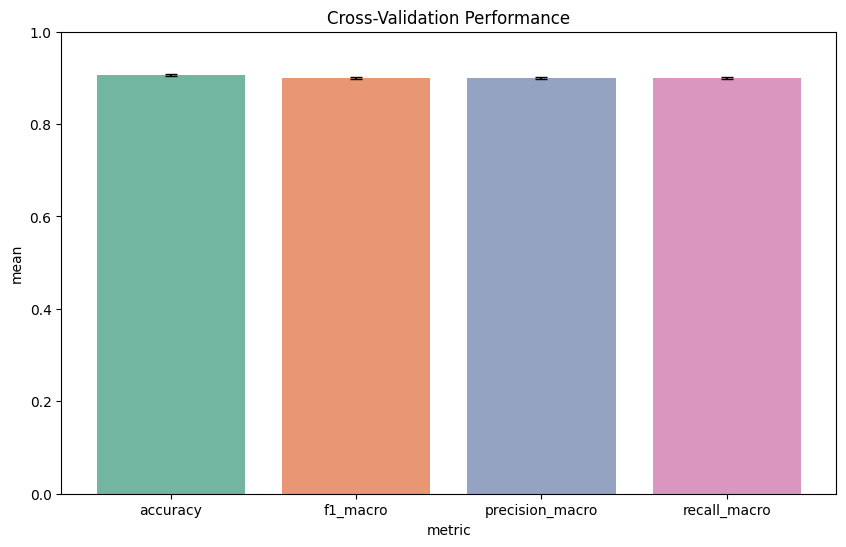

In [38]:

visualize_cv_performance(cv_stable_summary, title="Cross-Validation Performance").show()

Mit dieser, nun stabileren konfiguration erkennen wir mehrere Dinge.  
Die 5-Fold-Cross-Validation bestätigt die robuste Generalisierungsfähigkeit über verschiedene Datensätze hinweg.   
Wie in der Abbildung zu sehen ist, weisen alle vier Evaluierungsmetriken eine hohe und einheitliche Performance auf einem Niveau von knapp um 0,90 auf. 

Besonders hervorzuheben ist der kleine Standardfehler, der zeigt, dass der geschätzte Mittelwert der Modellleistung über die verschiedenen Folds hinweg nun präzise und stabil ist. Daraus können wir schliessen dass die Leistung des Modells nicht von einem günstigen Train-Test-Split abhängt, sondern sich das erlernte Wissen mit hoher statistischer Sicherheit auf ungesehene Daten übertragen lässt, und nicht mehr wie zuvor.

## Etappe 2: Hyperparameter Tuning
Im Folgenden sollst Du nun den Trainingsverlauf und die Modellperformance unter Änderung verschiedener Hyperparameter untersuchen. Hierzu sollst Du mind. 10 Hypothesen formulieren, Experimente durchführen, um die Hypothesen zu testen, und die Ergebnisse einordnen und reflektieren.

**Vorgehen pro Hypothese** 

Für jede Hypothese gehst du wie folgt vor:

1. Hypothese: Formuliere deine Erwartung dazu, was sich in der Modellperformance und/oder dem Trainingsverlauf ändert, wenn ein Hyperparameter verändert wird. Begründe diese Hypothese mit Hilfe deines theoretischen Wissens und gib eine entsprechende Referenz an.
2. Experiment: Definiere ein Experiment, mit welchem die Hypothese getestet werden kann und führe es durch.
3. Analyse/Reflexion: Analysiere die Ergebnisse daraufhin, ob sich die Hypothese bestätigt hat, und reflektiere darüber.

**Themengruppen für die Hypothesen**

Die Hypothesen sollen aus folgenden Bereichen gebildet werden:

* Modellkomplexität:
    * Anzahl Conv-Layer und/oder Anzahl linearer Layer (Modelltiefe)
    * Anzahl Filter pro Conv-Layer oder Anzahl Units in linearen Layern (Breite)
   
   Hinweis: Gegebenenfalls muss die Lernrate angepasst werden.
* Settings bei Conv-Layern:
    * Kernel Size
    * Pooling
* Regularisierung:
    * Dropout
    * Data Augmentation
* Verwendung von BatchNorm
* Initialisierung der Gewichte
* Verwendung des Adam Optimizers
* Transfer Learning

### Baseline

Das Baselinemodell ist das Ergebniss der vorhergenden Hyperparameteroptimierung. Um eine zuverlässige Abschätzung der Modellleistung und des adaptiven Fehlers zu erhalten, wurde es 15-mal mit verschiedenen Zufallswerten ausgeführt. Um die Hypothesen später annehmen oder ablehnen zu können, werden auch die anderen Experimente mehrmals durchgeführt.
Dadurch versuchen wir denn aleatorischen Fehler des Modeles abzubilden und einere genauere Aussage über die Performance dieser Archidektur auf diesen Daten zu treffen.  
Für die statistische Auswertung wird ein Signifikanzniveau von $\alpha = 0.05$ festgelegt. Als statistisches Prüfverfahren kommt der Paired Wilcoxon Signed-Rank Test zum Einsatz. Die Wahl fiel auf diesen nicht-parametrischen Test, da er im Gegensatz zu parametrischen Verfahren (wie dem T-Test) keine Normalverteilung und keine Homoskedastizität (Gleichheit der Varianzen) der beiden Gruppen voraussetzt. Die mathematische Formulierung des Tests lautet:

$$
W = \sum_{i=1}^{N_r} \left[ \operatorname{sgn}(x_{1,i} - x_{2,i}) \cdot R_i \right]
$$

wobei:
* $x_{1,i}, x_{2,i}$ die gepaarten Messwerte (z.~B. Performance von Baseline und Experiment im $i$-ten Run) darstellen.
* $N_r$ die Anzahl der Paare ist, bei denen die Differenz ungleich Null ist ($|x_{1,i} - x_{2,i}| \neq 0$).
* $\operatorname{sgn}$ die Vorzeichenfunktion (Signum-Funktion) ist.
* $R_i$ der Rang der absoluten Differenz $|x_{1,i} - x_{2,i}|$ nach aufsteigender Sortierung ist.

Eine Extrafunktionalität welche ich implementiert habe: das Gradient Clipping. Bei meinen vorherigen Testläufen ist, wie bereits erwähnt, aufgefallen, dass meine Gradienten immer wieder explodieren und meine Modelle nutzlose Ergebnisse liefern. Dies lag vermutlich an einer zu hohen Lernrate. Die um denn Faktor 10 tiefere Lernrate ist bereits bedeutend stabiler. In Kombination mit unglücklichen Randomseeds kann diese jedoch trotzdem zu dem zuvor genannten Problem führen. Durch Gradient Clipping erhoffe ich mir, das Training zu stabilisieren. Es bleibt allerdings optional und ist in allen Runs der ersten Etappe deaktiviert. Erst in Etappe zwei (ab hier) kommt es zum Einsatz. 

#### Implementation
- Gemeinsame Baseline: [src/hyp_tests/Baseline.py](../src/hyp_tests/Baseline.py)
- Model: [src/hyp_tests/model.py:7](../src/deeplearning/model.py:7)

In [65]:
baseline_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Baseline_HypTests",
            "config.is_summary_run": False,
        },
    )
)

results_dir = Path("../src/hyp_tests/results")
baseline_runs_path = results_dir / "baseline_runs.csv"
baseline_runs_df = pd.read_csv(baseline_runs_path)

In [66]:
# Build baseline-specific data frames from W&B runs
baseline_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant", "baseline"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in baseline_wandb_runs
    ]
)

baseline_history_frames = []
for run in baseline_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant", "baseline")
    history["repeat_idx"] = run.config.get("repeat_idx")
    baseline_history_frames.append(history)

baseline_history_df = pd.concat(baseline_history_frames, ignore_index=True)

# Use the CSV data for the summary plot
plot_df = baseline_wandb_final_df.copy()

wandb: WARNING A graphql request initiated by the public wandb API timed out (timeout=19 sec). Create a new API with an integer timeout larger than 19, e.g., `api = wandb.Api(timeout=29)` to increase the graphql timeout.


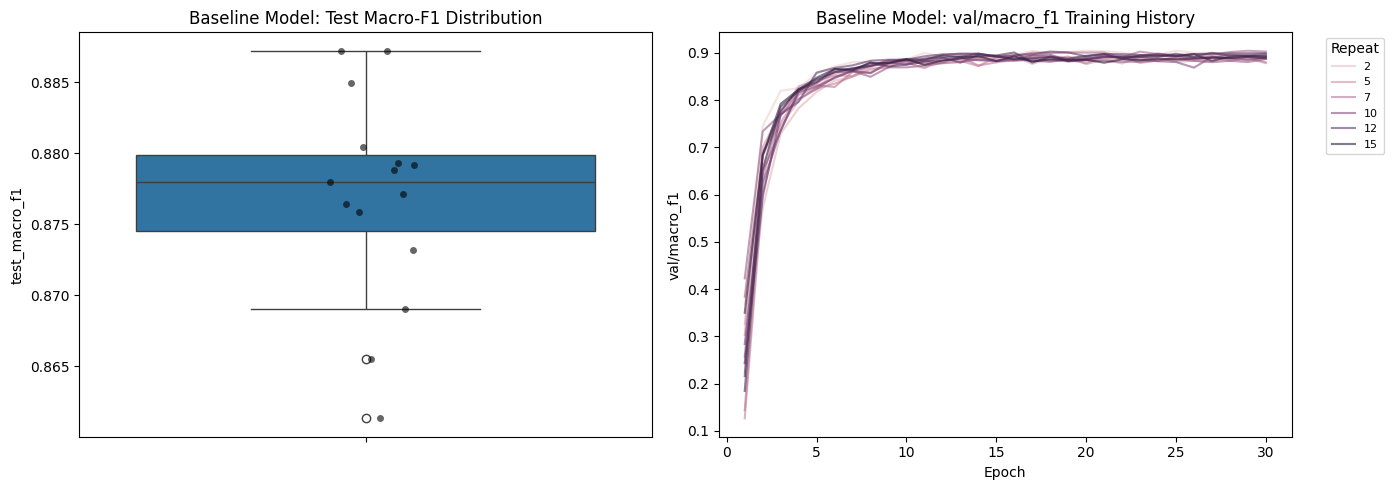

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=plot_df,
    y="test_macro_f1",
    ax=axes[0],
)
sns.stripplot(
    data=plot_df,
    y="test_macro_f1",
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Baseline Model: Test Macro-F1 Distribution")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=baseline_history_df,
    x="_step",
    y="val/macro_f1",
    hue="repeat_idx",
    estimator=None,
    ax=axes[1],
    alpha=0.6,
)
axes[1].set_title("Baseline Model: val/macro_f1 Training History")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")
axes[1].legend(title="Repeat", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

#### Interpretation
Wir erkennen, das von den 15 Runs kein einziger ein Resultat im F1 score von unter 0.85 hat. Das zeigt dass das Training stabil ist. 

### Hypothese 1:  Modelltiefe
Ein tieferes Model (mehr Layer) verbessert die Modellleistung auf dem SVHN-Datensatz.

$H_0: F(M_{\text{deep}}) \leq F(B)$

$H_1: F(M_{\text{deep}}) > F(B)$

#### Begründung
Ein moderat tieferes CNN erhöht die Kapazität des Netzwerks zur hierarchischen Merkmalsextraktion, da nun mehr schichten von Feature-extration layenr hintereinander sind.

Grundsätzlich sollten durch das zusätzliche Layer  komplexere / abstraktere Muster gelernt werden. 
Dies führt zu einer "schärferen" Repräsentation im Merkmalsraum, was wiederum die Klassifikationsleistung verbessert. 
Besonders bei ähnlichen Ziffern wird eine robustere Fehlertrennung erwartet.

#### Implementierung

- Modellarchitektur: [src/deeplearning/model.py:39](../src/deeplearning/model.py:39)
- Experiment-Runner: [src/hyp_tests/Hypothese_01.py](../src/hyp_tests/Hypothese_01.py)

Die gemeinsame Baseline wird einmal mit der besten Tuning-Konfiguration aus dem Notebook gespeichert (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) und in diesem Hypothesentest wiederverwendet.

Fuer $M_{\text{deep}}$ wurde das Baseline-Modell in `DeepCNN` kopiert und nur dort minimal angepasst:
- ein zusaetzlicher Convolution-Layer im zweiten Feature-Block (`32 -> 64 -> 128` statt direkt `32 -> 128`),
- Der Rest ist identisch zum Baselinemodel.


In [68]:
hyp01_runs_path = results_dir / "hypothesis_01_runs.csv"
hyp01_summary_path = results_dir / "hypothesis_01_summary.json"

# Data From Wandb
hypothese_01_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_01",
            "config.is_summary_run": False,
        },
    )

)

hyp01_variant_runs_df = pd.read_csv(hyp01_runs_path)
hyp01_runs_df = pd.concat([baseline_runs_df, hyp01_variant_runs_df], ignore_index=True)

In [69]:
hyp01_wandb_runs = baseline_wandb_runs + hypothese_01_variant_wandb_runs

hyp01_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp01_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp01_history_frames = []
for run in hyp01_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp01_history_frames.append(history)

hyp01_history_df = pd.concat(hyp01_history_frames, ignore_index=True)

display(hyp01_wandb_final_df)


,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,4dzspkkm,Hypothese_01-deep-repeat-01,deep,1,0.899470,0.879909,0.906348,0.823751
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,0afk4xe3,Hypothese_01-deep-repeat-02,deep,2,0.886032,0.873929,0.893788,0.839368
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,ah2q12o7,Hypothese_01-deep-repeat-03,deep,3,0.874233,0.850922,0.883140,1.005273
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,e5wf8y9h,Hypothese_01-deep-repeat-04,deep,4,0.899021,0.898721,0.906075,0.745483
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,luqrlfhi,Hypothese_01-deep-repeat-05,deep,5,0.884842,0.875801,0.895563,0.931820


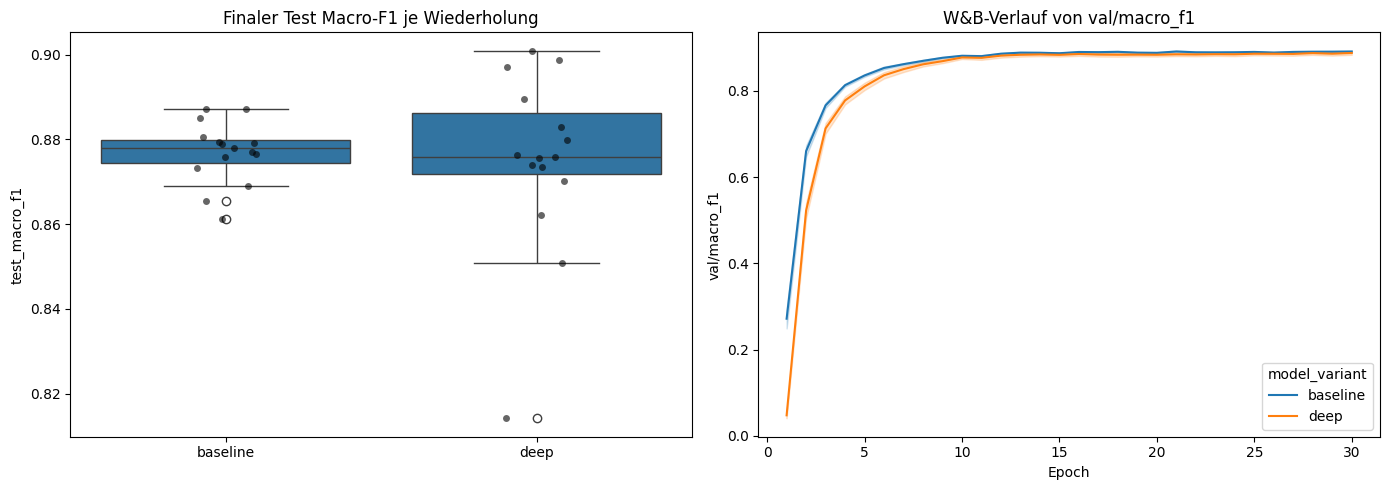

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp01_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'deep'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp01_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'deep'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp01_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_yscale("linear")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [71]:
baseline_h1_f1 = (
    hyp01_runs_df[hyp01_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
) 
deep_f1_ = (
    hyp01_runs_df[hyp01_runs_df["model_variant"] == "deep"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_02 = wilcoxon(
    x=baseline_h1_f1,
    y=deep_f1_,
    alternative="less"
)

print(f"baseline Mean: {baseline_h1_f1.mean():.4f}")
print(f"deep Mean: {deep_f1_.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_02.statistic}, p-value={wilcoxon_result_02.pvalue}")

baseline Mean: 0.8769
deep Mean: 0.8748
Wilcoxon signed-rank test result: statistic=64.0, p-value=0.5980224609375


#### Interpretation
Die Hypothese wird nicht bestätigt. Das tiefere Modell erreicht mit einem mittleren Test-Macro-F1-Wert von 0,8748 keinen Vorteil gegenüber der Baseline mit 0,8769.
Der Wilcoxon-Test ist mit p = 0,598 nicht signifikant, weshalb die Nullhypothese nicht verworfen werden kann.

Eine mögliche Erklärung ist, dass die zusätzliche Tiefe in dieser Architektur keinen Nutzen bringt, sondern die Optimierung erschwert. Bei kleinen 32×32-Bildern und einer bereits funktionierenden Baseline kann eine weitere Convolution-Schicht zu mehr Parametern, stärkerer Seed-Abhängigkeit und potenziell schlechterem Gradientenfluss führen. Ohne zusätzliche Hilfen führt mehr Tiefe daher nicht automatisch zu besserer Generalisierung.

### Hypothese 2: Modellbreite
Ein breiteres Modell verbessert die Modellleistung auf dem SVHN-Datensatz.

$H_0: F(M_{\text{wide}}) \leq F(B)$

$H_1: F(M_{\text{wide}}) > F(B)$

#### Begründung

Eine Erhöhung der Modellbreite durch mehr Filter pro Convolution-Layer und mehr Units im Fully-Connected-Layer erweitert die Kapazität des Netzwerks zur parallelen Merkmalsrepräsentation. 

Das Modell kann dadurch eine grössere Vielfalt an grundlegenden Texturen gleichzeitig erfassen.  Dies stärkt die Repräsentationskraft und sollte zu einem höheren Macro-F1-Score führen, sofern es nicht zu Overfitting kommt.

#### Implementierung

- Modellarchitekturen: [src/deeplearning/model.py:74](../src/deeplearning/model.py:74)
- Experiment-Runner: [src/hyp_tests/Hypothese_02.py](../src/hyp_tests/Hypothese_02.py)

Für $M_{\text{wide}}$ wurde das Baseline-Modell in `WideCNN` kopiert und nur in der Breite angepasst:
- breitere Convolution-Layer (`3 -> 32 -> 64 -> 256` statt `3 -> 16 -> 32 -> 128`),
- breiterer Klassifikationskopf (`256*8*8 -> 1024 -> 192 -> 10` statt `128*8*8 -> 512 -> 96 -> 10`),
- Ansonsten alles identisch

In [72]:
hyp02_runs_path = results_dir / "hypothesis_02_runs.csv"
hyp02_summary_path = results_dir / "hypothesis_02_summary.json"

hyp02_variant_runs_df = pd.read_csv(hyp02_runs_path)
hyp02_runs_df = pd.concat([baseline_runs_df, hyp02_variant_runs_df], ignore_index=True)

hypothese_02_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_02",
            "config.is_summary_run": False,
        },
    )
)

In [73]:
hyp02_wandb_runs = baseline_wandb_runs + hypothese_02_variant_wandb_runs

hyp02_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp02_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp02_history_frames = []
for run in hyp02_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp02_history_frames.append(history)

hyp02_history_df = pd.concat(hyp02_history_frames, ignore_index=True)


display(hyp02_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,uqsydvgo,Hypothese_02-wide-repeat-01,wide,1,0.901968,0.882605,0.908259,0.687556
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,ftcz9cd4,Hypothese_02-wide-repeat-02,wide,2,0.902674,0.886134,0.909761,0.650464
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,66j2k5wk,Hypothese_02-wide-repeat-03,wide,3,0.913633,0.895670,0.916997,0.708782
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,2av7rtsw,Hypothese_02-wide-repeat-04,wide,4,0.890450,0.880856,0.898976,0.793881
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,ifl42qad,Hypothese_02-wide-repeat-05,wide,5,0.889330,0.877553,0.898294,0.750102


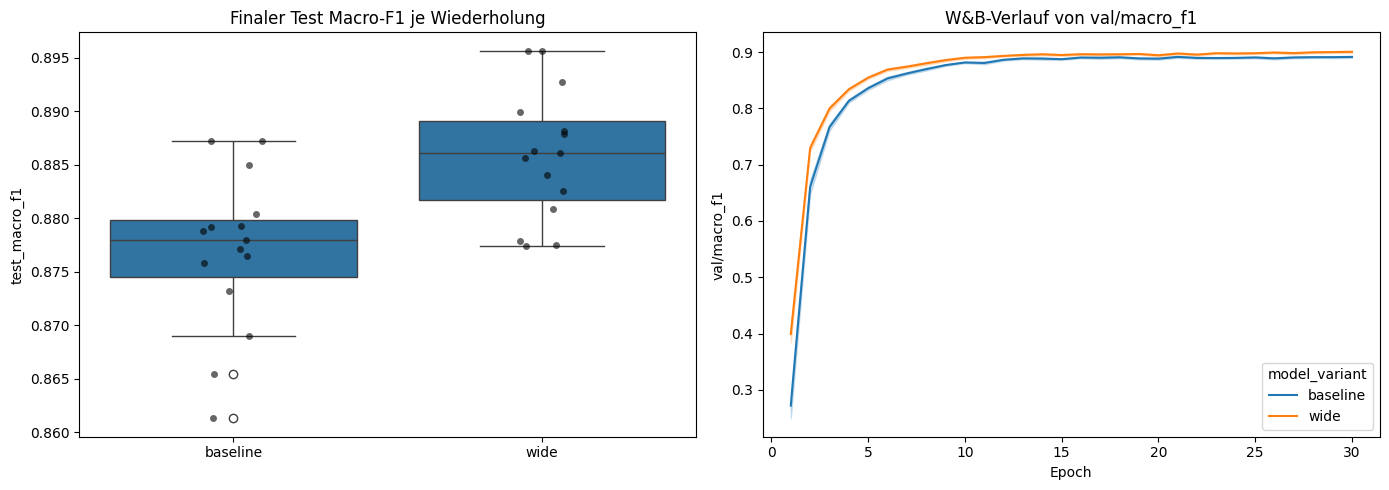

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp02_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'wide'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp02_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'wide'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp02_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [75]:
baseline_h2_f1 = (
    hyp02_runs_df[hyp02_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
wide_f1_ = (
    hyp02_runs_df[hyp02_runs_df["model_variant"] == "wide"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_02 = wilcoxon(
    x=baseline_h2_f1,
    y=wide_f1_,
    alternative="less"
)

print(f"baseline Mean: {baseline_h2_f1.mean():.4f}")
print(f"wide Mean: {wide_f1_.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_02.statistic}, p-value={wilcoxon_result_02.pvalue}")

baseline Mean: 0.8769
wide Mean: 0.8859
Wilcoxon signed-rank test result: statistic=4.0, p-value=0.000213623046875


#### Interpretation
Die Hypothese wird bestätigt. Das breitere Modell verbessert den mittleren Test-Macro-F1-Wert von 0,8769 auf 0,8859 und der Wilcoxon-Test ist mit p = 0,00021 signifikant. Die zusätzliche Breite scheint dem Modell also dabei zu helfen, mehr parallele visuelle Merkmale zu lernen.

Der Effekt ist jedoch eher moderat. Die Verbesserung beträgt ca. 0,009 Macro-F1-Punkte. Daraus lässt sich ableiten, dass die Baseline teilweise kapazitätslimitiert ist, jedoch nicht stark. Mehr Filter und ein größerer Klassifikationskopf verbessern die Repräsentationsfähigkeit, erhöhen aber auch den Rechenaufwand und die Parameterzahl. Für eine praktische Modellwahl müsste man deshalb den Performancegewinn und die Modellgröße gegeneinander abwägen.


### Hypothese 3: Kernelgrösse
Die Wahl einer kleineren Kernelgrösse verschlechtert die Modellleistung auf dem SVHN-Datensatz.

$H_0: F(M_{k=3}) \geq F(B)$

$H_1: F(M_{k=3}) < F(B)$

#### Begründung
Ein 3x3-Convolution-Layer hat ein kleineres rezeptives Feld wie ein 5x5-Layer. Bei SVHN können jedoch breitere lokale Kontexte hilfreich sein, da die Ziffern klein sind, Hintergrundinformationen enthalten und teilweise durch Beleuchtung, Randbereiche oder benachbarte Ziffern beeinflusst werden. Ein zu kleines rezeptives Feld in den ersten Schichten kann diese Kontextinformationen nicht optimal erfassen.

#### Implementierung

- Modellarchitekturen: [src/deeplearning/model.py:107](../src/deeplearning/model.py:107)
- Experiment-Runner: [src/hyp_tests/Hypothese_03.py](../src/hyp_tests/Hypothese_03.py)

Für $M_{k=3}$ wurde das Baseline-Modell in `Kernel3CNN` kopiert und nur bei der Kernelgroesse angepasst:
- alle drei Convolution-Layer verwenden `3x3`-Kernel mit `padding=1` statt `5x5` mit `padding=2`,
- Tiefe, Kanalzahlen, Pooling und Klassifikationskopf bleiben identisch zum Baseline-Modell,
- der Rest ist identisch.



In [76]:
hyp03_runs_path = results_dir / "hypothesis_03_runs.csv"
hyp03_summary_path = results_dir / "hypothesis_03_summary.json"

hyp03_variant_runs_df = pd.read_csv(hyp03_runs_path)
hyp03_runs_df = pd.concat([baseline_runs_df, hyp03_variant_runs_df], ignore_index=True)

hypothese_03_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_03",
            "config.is_summary_run": False,
        },
    )
)

In [77]:
hyp03_wandb_runs = baseline_wandb_runs + hypothese_03_variant_wandb_runs

hyp03_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp03_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp03_history_frames = []
for run in hyp03_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp03_history_frames.append(history)

hyp03_history_df = pd.concat(hyp03_history_frames, ignore_index=True)

display(hyp03_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,cedqekld,Hypothese_03-k3-repeat-01,k3,1,0.876458,0.845146,0.883823,0.528095
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,t0bhi6dn,Hypothese_03-k3-repeat-02,k3,2,0.882826,0.853534,0.890785,0.654527
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,nagi7lla,Hypothese_03-k3-repeat-03,k3,3,0.878135,0.849179,0.885188,0.561380
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,24bcx0io,Hypothese_03-k3-repeat-04,k3,4,0.871292,0.859356,0.878498,0.631872
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,26l9cdtz,Hypothese_03-k3-repeat-05,k3,5,0.882729,0.868359,0.890785,0.580501


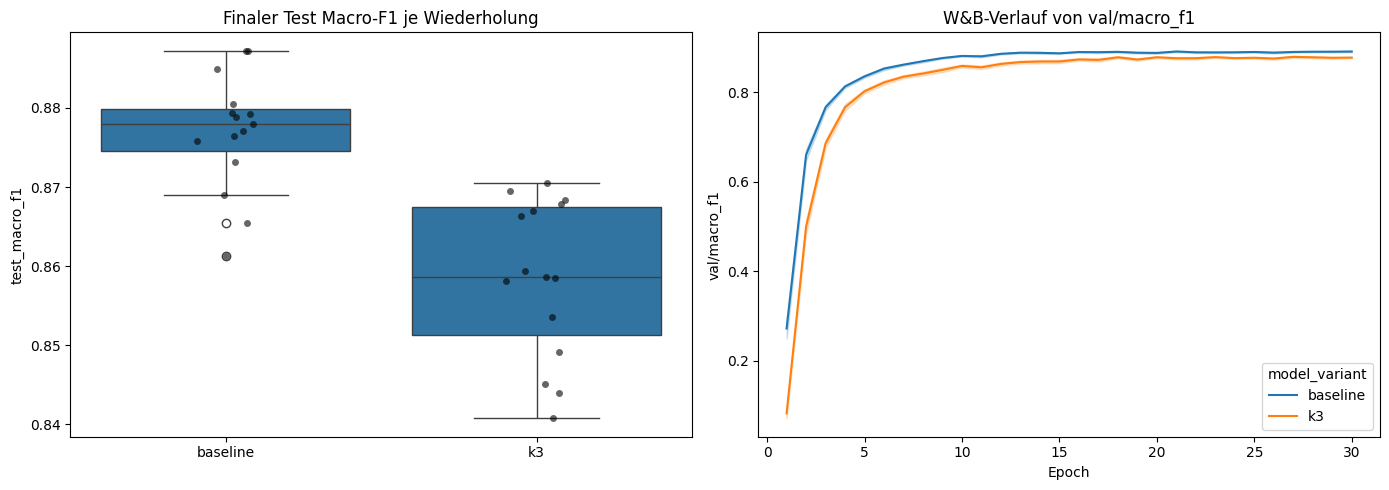

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp03_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'k3'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp03_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'k3'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp03_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [79]:
baseline_h3_f1 = (
    hyp03_runs_df[hyp03_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

k3_f1_ = (
    hyp03_runs_df[hyp03_runs_df["model_variant"] == "k3"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

# Normalerweise würde man H1: k3 > baseline testen, aber da ich bereits ind der Grafik sehe das K3 schlechter ist, teste ich hier H1: k3 != baseline, also two sided
wilcoxon_result_03 = wilcoxon(
    x=baseline_h3_f1,
    y=k3_f1_,
    alternative="greater"
)

print(f"baseline Mean: {baseline_h3_f1.mean():.4f}")
print(f"wide Mean: {k3_f1_.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_03.statistic}, p-value={wilcoxon_result_03.pvalue}")#

baseline Mean: 0.8769
wide Mean: 0.8585
Wilcoxon signed-rank test result: statistic=120.0, p-value=3.0517578125e-05


#### Intepretation

Die Hypothese wird bestätigt. Das Modell mit 3x3-Kernels erreicht nur einen mittleren Test-Macro-F1 von 0.8585 gegenüber 0.8769 bei der Baseline. Der Unterschied ist signifikant

Die kleineren Kernel reduzieren zwar die Parameterzahl und wirken damit regulierend, verringern aber auch die lokale Kontextaufnahme. In dieser Architektur scheint der Informationsverlust durch das kleinere rezeptive Feld stärker zu sein als der mögliche Regularisierungsvorteil.

### Hypothese 4: Poolingverhalten

Späteres pooling verbessert die Modellperformance auf dem SVHN-Trainingsset.

$H_0: F(M_{\text{pool-late}}) \leq F(B)$

$H_1: F(M_{\text{pool-late}}) > F(B)$

#### Begründung

Der SVHN-Datensatz enthält sehr kleine Bildausschnitte mit teils feinen und dicht beieinanderliegenden Zifferndetails.  
Ein zu frühes Pooling, effektiv ein Downsampling, reduziert die räumliche Auflösung und verwirft exakte Positionsdaten, wodurch Merkmale verloren gehen können.  
Durch das spätere Pooling bleiben die Feature-Maps in den späteren Convolution-Layern räumlich doppelt so so gross. Kleine und Präzisse merkmale sollten dadch vom Model auch später noch besser erkannt und verarbeitet werden können. 

#### Implementierung

- Modellarchitekturen: [src/deeplearning/model.py:140](../src/deeplearning/model.py:140)
- Experiment-Runner: [src/hyp_tests/Hypothese_04.py](../src/hyp_tests/Hypothese_04.py)

Fuer $M_{\text{pool-late}}$ wurde das Baseline-Modell in `PoolLateCNN` kopiert und nur beim Pooling angepasst:
- die erste Pooling-Stufe nach dem zweiten Convolution-Layer entfällt,
- es bleibt nur ein spaeteres MaxPooling nach dem dritten Convolution-Layer erhalten,
- der erste Linear-Layer wird nur wegen der groesseren Feature-Map von `128*8*8` auf `128*16*16` angepasst; die restliche Klassifikationsstruktur bleibt gleich,

In [80]:
hyp04_runs_path = results_dir / "hypothesis_04_runs.csv"
hyp04_summary_path = results_dir / "hypothesis_04_summary.json"

hyp04_variant_runs_df = pd.read_csv(hyp04_runs_path)
hyp04_runs_df = pd.concat([baseline_runs_df, hyp04_variant_runs_df], ignore_index=True)

hypothese_04_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_04",
            "config.is_summary_run": False,
        },
    )
)

In [81]:
hyp04_wandb_runs = baseline_wandb_runs + hypothese_04_variant_wandb_runs

hyp04_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp04_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp04_history_frames = []
for run in hyp04_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp04_history_frames.append(history)

hyp04_history_df = pd.concat(hyp04_history_frames, ignore_index=True)

display(hyp04_wandb_final_df)


,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,kgstx66q,Hypothese_04-pool-late-repeat-01,pool-late,1,0.899961,0.881051,0.906621,0.798759
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,irc65pz7,Hypothese_04-pool-late-repeat-02,pool-late,2,0.905014,0.880692,0.910990,0.753113
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,0tfbwafq,Hypothese_04-pool-late-repeat-03,pool-late,3,0.883628,0.851713,0.889966,0.799947
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,pmwlhjmt,Hypothese_04-pool-late-repeat-04,pool-late,4,0.897996,0.883902,0.904300,0.840011
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,mu1dvznm,Hypothese_04-pool-late-repeat-05,pool-late,5,0.883602,0.865010,0.891468,0.921669


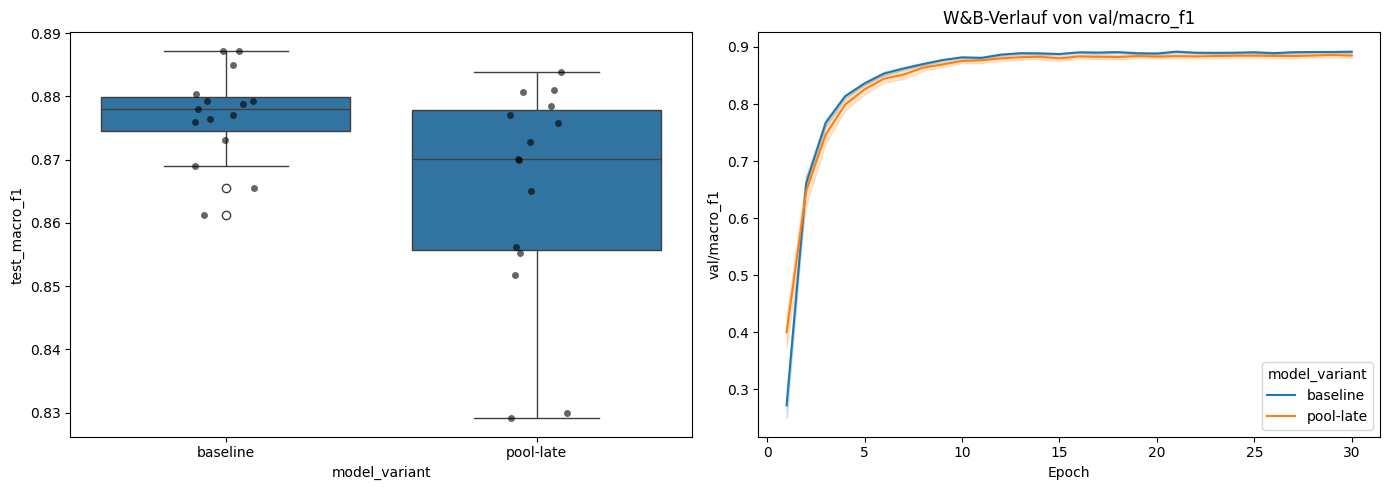

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp04_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'pool-late'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp04_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'pool-late'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

sns.lineplot(
    data=hyp04_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [85]:
baseline_h4_f1 = (
    hyp04_runs_df[hyp04_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
pool_late_f1 = (
    hyp04_runs_df[hyp04_runs_df["model_variant"] == "pool-late"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_04 = wilcoxon(
    x=baseline_h4_f1,
    y=pool_late_f1,
    alternative="less"
)

print(f"baseline Mean: {baseline_h4_f1.mean():.4f}")
print(f"pool-late Mean: {pool_late_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_04.statistic}, p-value={wilcoxon_result_04.pvalue}")

baseline Mean: 0.8769
pool-late Mean: 0.8651
Wilcoxon signed-rank test result: statistic=110.0, p-value=0.998992919921875


#### Interpretation
Die Hypothese wird nicht bestätigt. Das spätere Pooling verschlechtert den mittleren Test-Macro-F1-Wert von 0,8769 auf 0,8651 und der Wilcoxon-Test zeigt mit p = 0,0026 einen signifikanten Unterschied.

Die Ergebnisse deuten darauf hin, dass frühes Pooling in diesem Fall eine nützliche Regularisierung darstellt. Es reduziert irrelevante lokale Details, Hintergrundrauschen und exakte Pixelabhängigkeiten, während gleichzeitig eine gewisse Translationsinvarianz erzeugt wird.

Zusätzlich vergrößert das spätere Pooling die Feature-Maps vor dem Fully-Connected-Teil. Dadurch steigt die Anzahl der Eingabefeatures im Klassifikationskopf deutlich, was die Optimierung erschwert und Overfitting begünstigt. Für SVHN scheint die Baseline-Balance aus früher Dimensionsreduktion und ausreichender räumlicher Information besser geeignet zu sein.

### Hypothese 5: Dropout
Die Einführung von einem moderaten Dropout (0.3), wird die Modellperformance auf dem SVHN-Datensatz verbessert.

$H_0: F(M_{\text{drop}=0.3}) \leq F(B)$

$H_1: F(M_{\text{drop}=0.3}) > F(B)$

#### Begründung
Durch moderates Dropout sollte die Co-Adaptation reduziert und das Overfitting im Klassifikationskopf gedämpft werden. Vor allem wird eine bessere Generalisierung auf dem Testset erwartet.

Ein vollverknüpfter Klassifikationskopf besitzt die höchstmögliche Dichte an lernbaren Parametern. 
Dadurch neigen solche Netzwerke besonders stark dazu, Rauschen und Muster der Trainingsdaten auswendig zu lernen (Overfitting).  
Durch die erzwungene Reduktion muss das Netzwerk nun redundante Repräsentationen erlernen, was Co-Adaptation verhindern kann. Dabei verlassen sich Neuronen auf die Fehler anderer Neuronen.  
Dropout wirkt somit von Nodes regularisierend, da das Modell beim Trainieren nicht immer wieder ähnliche Signale erhält.

#### Implementierung

- Modellarchitekturen: [src/deeplearning/model.py:172](../src/deeplearning/model.py:172)
- Experiment-Runner: [src/hyp_tests/Hypothese_05.py](../src/hyp_tests/Hypothese_05.py)

Fuer $M_{\text{drop}=0.3}$ wurde das Baseline-Modell in `DropoutCNN` kopiert und nur im Klassifikationskopf angepasst:
- nach jeder ReLU-Aktivierung der beiden Hidden-Layer im Classifier wurde `Dropout(p=0.3)` eingefuegt,
- Convolution-Teil, Layerbreiten und Pooling bleiben identisch zum Baseline-Modell,
- Ansonten bleibt alles gleich.

In [86]:
hyp05_runs_path = results_dir / "hypothesis_05_runs.csv"
hyp05_summary_path = results_dir / "hypothesis_05_summary.json"

hyp05_variant_runs_df = pd.read_csv(hyp05_runs_path)
hyp05_runs_df = pd.concat([baseline_runs_df, hyp05_variant_runs_df], ignore_index=True)

hypothese_05_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_05",
            "config.is_summary_run": False,
        },
    )
)

In [87]:
hyp05_wandb_runs = baseline_wandb_runs + hypothese_05_variant_wandb_runs

hyp05_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp05_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp05_history_frames = []
for run in hyp05_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp05_history_frames.append(history)

hyp05_history_df = pd.concat(hyp05_history_frames, ignore_index=True)

display(hyp05_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,tsz9x61p,Hypothese_05-dropout-repeat-01,dropout-0.3,1,0.918616,0.908359,0.924096,0.320388
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,3gfqwn1u,Hypothese_05-dropout-repeat-02,dropout-0.3,2,0.918436,0.905532,0.923549,0.344125
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,jccf4gf1,Hypothese_05-dropout-repeat-03,dropout-0.3,3,0.923941,0.899851,0.927509,0.331966
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,v9py5ha2,Hypothese_05-dropout-repeat-04,dropout-0.3,4,0.905357,0.900244,0.912355,0.389729
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,okujg4wn,Hypothese_05-dropout-repeat-05,dropout-0.3,5,0.915798,0.898509,0.922457,0.363247


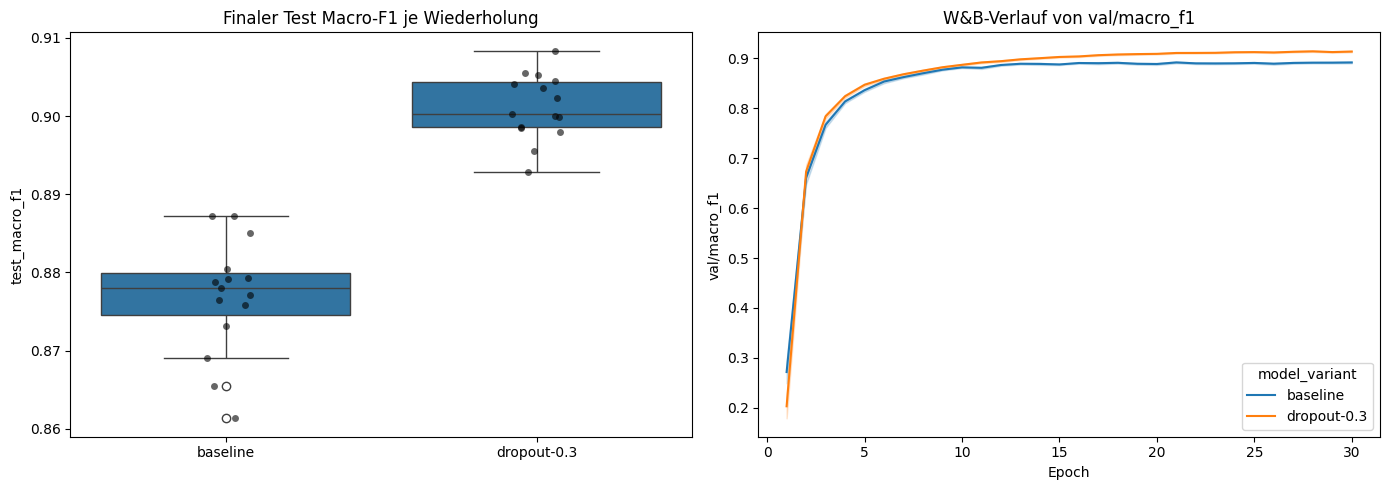

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp05_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'dropout-0.3'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp05_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'dropout-0.3'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp05_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [89]:
baseline_h5_f1 = (
    hyp05_runs_df[hyp05_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
dropout_03_f1 = (
    hyp05_runs_df[hyp05_runs_df["model_variant"] == "dropout-0.3"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_05 = wilcoxon(
    x=baseline_h5_f1,
    y=dropout_03_f1,
    alternative="less"
)

print(f"baseline Mean: {baseline_h5_f1.mean():.4f}")
print(f"dropout-0.3 Mean: {dropout_03_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_05.statistic}, p-value={wilcoxon_result_05.pvalue}")

baseline Mean: 0.8769
dropout-0.3 Mean: 0.9012
Wilcoxon signed-rank test result: statistic=0.0, p-value=3.0517578125e-05


#### Interpretation
Die Hypothese wird bestätigt. Durch Dropout mit p = 0,3 verbessert sich der mittlere Test-Macro-F1-Wert von 0,8769 auf 0,9012, was einen statistisch signifikanten Unterschied darstellt. Dies spricht dafür, dass die Baseline insbesondere im vollverknüpften Klassifikationskopf von Regularisierung profitiert.

Dropout verhindert, dass sich einzelne Neuronen zu stark auf spezifische Aktivierungsmuster verlassen. Dadurch muss das Modell robustere und redundant nutzbare Repräsentationen lernen. Gerade beim relativ großen Fully-Connected-Teil der Baseline reduziert dies das Overfitting und verbessert die Generalisierung auf ungesehene Testdaten.

### Hypothese 6: Data Augmentation
Die Einführung von Data Augmentation verbessert die Modelperformance auf dem SVHN-Datensatz.

$H_0: F(M_{\text{aug}}) \leq F(B)$

$H_1: F(M_{\text{aug}}) > F(B)$

#### Begründung
Leichte Augmentationen wie kleine Translationen, Rotationen oder Helligkeitsänderungen sollten durch das Einbringen kontrollierter Variationen die Varianz der Trainingsdaten erhöhen. 

Erhofft wird ein höherer Macro-F1 und ein geringerer Generalisierungsfehler, da das Modell nun optimalerweise robuste Merkmale erlernt, statt sich auf spezifische Pixelpositionen oder Lichtverhältnisse zu fixieren, was Overfitting effektiv reduziert.


#### Implementierung

- Trainingslogik mit optionalem `val_loader`: [src/training.py](../src/training.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_06.py](../src/hyp_tests/Hypothese_06.py)

Fuer $M_{\text{aug}}$ bleibt die Modellarchitektur identisch zum Baseline-Modell; veraendert wird nur die Dateneingabe im Training:
* auf dem Trainingssplit werden leichte Augmentationen angewendet: `RandomAffine(degrees=8, translate=(0.08, 0.08))` und `ColorJitter(brightness=0.15, contrast=0.10)`,
* der Validierungssplit bleibt ohne Augmentation und wird nur normalisiert.

In [90]:
hyp06_runs_path = results_dir / "hypothesis_06_runs.csv"
hyp06_summary_path = results_dir / "hypothesis_06_summary.json"

hyp06_variant_runs_df = pd.read_csv(hyp06_runs_path)
hyp06_runs_df = pd.concat([baseline_runs_df, hyp06_variant_runs_df], ignore_index=True)

hypothese_06_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_06",
            "config.is_summary_run": False,
        },
    )
)

In [91]:
hyp06_wandb_runs = baseline_wandb_runs + hypothese_06_variant_wandb_runs

hyp06_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp06_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp06_history_frames = []
for run in hyp06_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp06_history_frames.append(history)

hyp06_history_df = pd.concat(hyp06_history_frames, ignore_index=True)

display(hyp06_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
15,ue2zvfxm,Hypothese_06-aug-repeat-01,aug,1,0.926177,0.926342,0.929556,0.252100
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
16,v1z0li5m,Hypothese_06-aug-repeat-02,aug,2,0.930306,0.928549,0.934334,0.233786
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
17,6qbtuwc9,Hypothese_06-aug-repeat-03,aug,3,0.927589,0.915745,0.929693,0.256716
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
18,9ifsb4nt,Hypothese_06-aug-repeat-04,aug,4,0.925445,0.918467,0.930375,0.256663
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
19,7qtu7ay9,Hypothese_06-aug-repeat-05,aug,5,0.926919,0.927532,0.931877,0.239795
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896


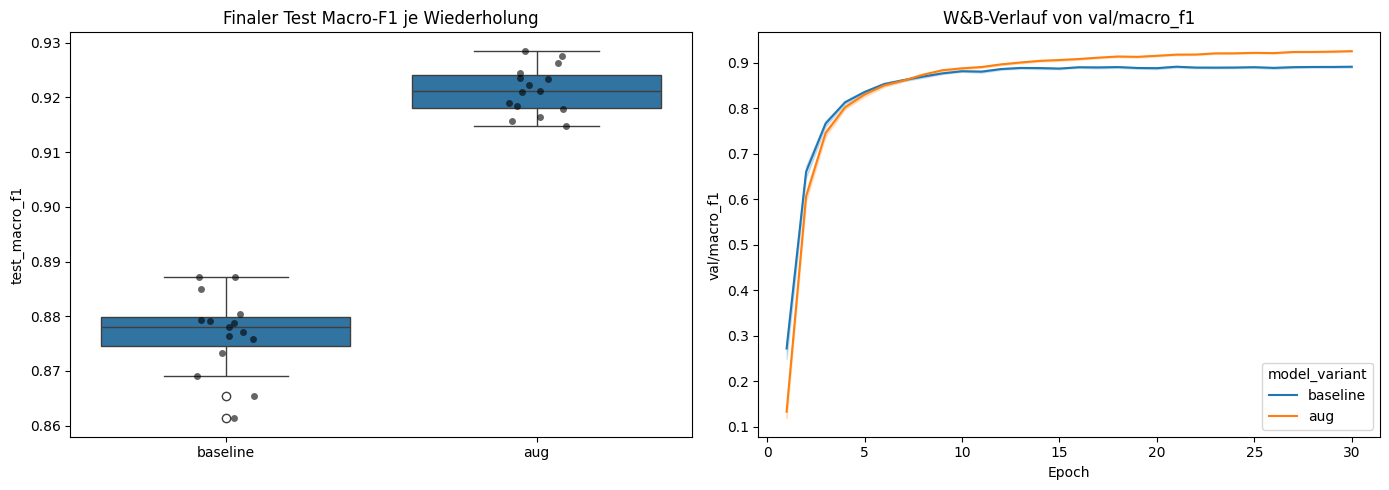

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp06_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'aug'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp06_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'aug'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp06_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [93]:
baseline_h6_f1 = (
    hyp06_runs_df[hyp06_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
aug_f1 = (
    hyp06_runs_df[hyp06_runs_df["model_variant"] == "aug"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_06 = wilcoxon(
    x=baseline_h6_f1,
    y=aug_f1,
    alternative="less"
)

print(f"baseline Mean: {baseline_h6_f1.mean():.4f}")
print(f"aug Mean: {aug_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_06.statistic}, p-value={wilcoxon_result_06.pvalue}")

baseline Mean: 0.8769
aug Mean: 0.9214
Wilcoxon signed-rank test result: statistic=0.0, p-value=3.0517578125e-05


#### Interpretation

Die Hypothese wird eindeutig bestätigt. Mit einem mittleren Test-Macro-F1 von 0,9214 erzielt Data Augmentation die stärkste Verbesserung aller getesteten Varianten. Der Unterschied zur Baseline ist signifikant.

Dies deutet darauf hin, dass die Baseline zu stark auf konkrete Pixelpositionen, Helligkeitsverhältnisse und kleine visuelle Eigenheiten des Trainingssets reagiert. Durch leichte Rotationen, Translationen und Farbänderungen sieht das Modell während des Trainings mehrere plausible Varianten desselben Musters. Dadurch lernt es robustere Merkmale für Ziffernformen statt nur trainingsspezifische Bilddetails.

Auffällig ist insbesondere, dass sich dieser Vorteil erst in späteren Epochen zeigt. Dies spricht dafür, dass die Augmentation nicht nur den Trainingsstart beeinflusst, sondern vor allem die Generalisierung verbessert und das Overfitting reduziert.

### Hypothese 7: Batch Normalization

Die Einführung von Batch Normalization verbessert die Modellperformance auf dem SVHN-Datensatz.


$H_0: F(M_{\text{BN}}) \leq F(B)$

$H_1: F(M_{\text{BN}}) > F(B)$

#### Begründung
Die Integration von Batch Normalization soll die Optimierungslandschaft des Modells glätten und die Konvergenz während des Trainings beschleunigen. 

Durch die Stabilisierung der Aktivitätsverteilungen innerhalb der Schichten (Reduzierung des Internal Covariate Shift) wird ein stabilerer und glatterer Trainingsverlauf erwartet. In der Folge erhofft man sich eine effizientere Gradientenübertragung und somit eine Steigerung des finalen Macro-$F_1$-Scores im Vergleich zur Baseline.

#### Implementierung


- Modellvarianten: [src/deeplearning/model.py:207](../src/deeplearning/model.py:207)
- Experiment-Runner: [src/hyp_tests/Hypothese_07.py](../src/hyp_tests/Hypothese_07.py)

Auch für $M_{\text{BN}}$ bleibt die Grundarchitektur des Baseline-Modells unveraendert. Ergaenzt werden nur `BatchNorm2d`-Schichten direkt nach den drei Convolution-Layern. 
Damit ändert sich gegenueber der Baseline nur das Normalisierungsverhalten innerhalb des CNN-Feature-Extractors

In [94]:
hyp07_runs_path = results_dir / "hypothesis_07_runs.csv"
hyp07_summary_path = results_dir / "hypothesis_07_summary.json"

hyp07_variant_runs_df = pd.read_csv(hyp07_runs_path)
hyp07_runs_df = pd.concat([baseline_runs_df, hyp07_variant_runs_df], ignore_index=True)

hypothese_07_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_07",
            "config.is_summary_run": False,
        },
    )
)

In [95]:
hyp07_wandb_runs = baseline_wandb_runs + hypothese_07_variant_wandb_runs

hyp07_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp07_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp07_history_frames = []
for run in hyp07_wandb_runs:    
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp07_history_frames.append(history)

hyp07_history_df = pd.concat(hyp07_history_frames, ignore_index=True)

display(hyp07_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,9styiryb,Hypothese_07-batchnorm-repeat-01,batchnorm,1,0.923290,0.912666,0.927509,0.350326
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,83yn31tt,Hypothese_07-batchnorm-repeat-02,batchnorm,2,0.918171,0.905879,0.922594,0.377815
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,32lpu6x3,Hypothese_07-batchnorm-repeat-03,batchnorm,3,0.927487,0.907856,0.929829,0.367045
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,2tden7tt,Hypothese_07-batchnorm-repeat-04,batchnorm,4,0.914331,0.907633,0.918498,0.442759
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,k64fqxs5,Hypothese_07-batchnorm-repeat-05,batchnorm,5,0.902868,0.896347,0.909761,0.434670


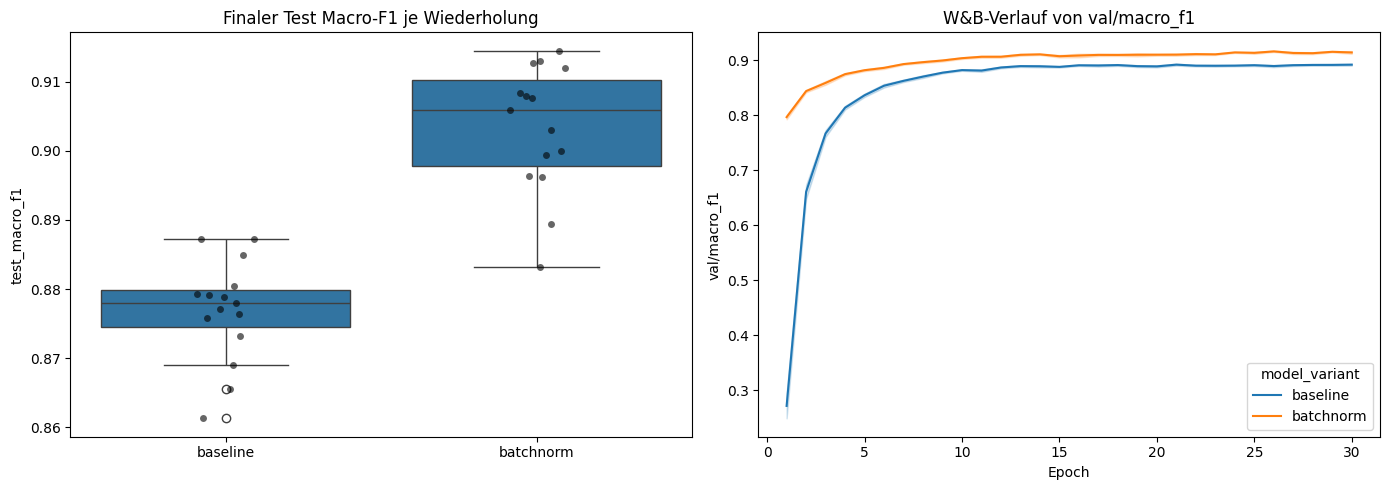

In [96]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp07_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'batchnorm'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp07_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'batchnorm'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp07_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()

In [97]:
baseline_h7_f1 = (
    hyp07_runs_df[hyp07_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
batchnorm_f1 = (
    hyp07_runs_df[hyp07_runs_df["model_variant"] == "batchnorm"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_07 = wilcoxon(
    x=baseline_h7_f1,
    y=batchnorm_f1,
    alternative="less"
)

print(f"baseline Mean: {baseline_h7_f1.mean():.4f}")
print(f"batchnorm Mean: {batchnorm_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_07.statistic}, p-value={wilcoxon_result_07.pvalue}")

baseline Mean: 0.8769
batchnorm Mean: 0.9033
Wilcoxon signed-rank test result: statistic=0.0, p-value=3.0517578125e-05


#### Interpretation
Die Hypothese wird bestätigt. Batch Normalization verbessert den mittleren Test-Macro-F1-Score von 0,8769 auf 0,9033 und der Wilcoxon-Test ist signifikant. Auch der Trainingsverlauf zeigt, dass das Modell mit Batch Normalization schneller und stabiler konvergiert.

Eine plausible Erklärung hierfür ist, dass BatchNorm die Aktivierungsverteilungen innerhalb der Konvolutionsblöcke stabilisiert. Dadurch werden die Gradienten besser kontrollierbar und das Modell reagiert weniger empfindlich auf die initialen Gewichte und die Lernrate. Zusätzlich wirkt BatchNorm durch die Batch-Statistiken leicht regularisierend, was ebenfalls zur besseren Generalisierung beitragen kann.

Interessant ist, dass diese Verbesserung bereits in frühen Epochen eintritt.

### Hypothese 8: Initialisierungsfunktion
Ein mit der He-Initialisierung trainiertes Modell erzielt auf dem SVHN-Datensatz eine höhere Performance als ein mit der Xavier-Initialisierung trainiertes Modell.

$H_0: F(M_{\text{He}}) \leq F(M_{\text{Xav}})$

$H_1: F(M_{\text{He}}) > F(M_{\text{Xav}})$

#### Begründung
Die Wahl der Initialisierungsfunktion hat einen maßgeblichen Einfluss auf den Signalfluss sowie die Varianz der Aktivierungen zu Beginn des Trainings. Da das vorliegende Modell ausschließlich ReLU-Aktivierungsfunktionen verwendet, ist die Xavier-Initialisierung theoretisch suboptimal.  
Die Xavier-Methode basiert auf der Annahme linearer oder linearisierter Aktivierungsfunktionen. Bei der asymmetrischen ReLU-Funktion, die negative Werte auf Null projiziert, führt dies mathematisch zu einer Halbierung der Varianz pro Schicht. In der Folge kann der Gradientenfluss gehemmt und das Risiko für das Problem sterbender Neuronen (Dying ReLUs) erhöht werden.

Die He-Initialisierung (auch Kaiming-Initialisierung) kompensiert diesen Effekt, indem sie die Gewichte mit einer doppelt so großen Varianz skaliert ($\frac{2}{\text{fan\_in}}$ statt $\frac{1}{\text{fan\_in}}$). Dadurch wird eine stabilere Gradientenübertragung in den ersten Epochen und ein robusterer Trainingsstart gewährleistet. Langfristig führt dies zu einer präziseren Konvergenz und folglich zu einer höheren Endleistung, gemessen am Macro-$F_1$-Score.

#### Implementierung

- Modellvarianten: [src/deeplearning/model.py:270](../src/deeplearning/model.py:270)
- Experiment-Runner: [src/hyp_tests/Hypothese_08.py](../src/hyp_tests/Hypothese_08.py)

Die gespeicherte Baseline wird hier nicht als Vergleichsmodell verwendet, sondern nur als Quelle fuer die beste Tuning-Konfiguration aus dem Notebook (`learning_rate=0.05`, `batch_size=128`, `epochs=30`) sowie fuer die festen Repeat-Seeds.

Verglichen werden zwei ansonsten identische Baseline-Modelle:
- $M_{\text{Xav}}$: Baseline-Architektur mit `Xavier`-Initialisierung aller Convolution- und Linear-Layer,
- $M_{\text{He}}$: dieselbe Architektur mit `He`-Initialisierung derselben Layer.

Damit unterscheidet sich zwischen beiden Modellen ausschliesslich die Initialisierungsfunktion; Architektur, Daten, Trainingseinstellungen und Auswertung bleiben gleich.


In [98]:
hyp08_runs_path = results_dir / "hypothesis_08_runs.csv"
hyp08_summary_path = results_dir / "hypothesis_08_summary.json"

hyp08_runs_df = pd.read_csv(hyp08_runs_path)

hyp08_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_08",
            "config.is_summary_run": False,
        },
    )
)

In [99]:
hyp08_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp08_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp08_history_frames = []
for run in hyp08_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp08_history_frames.append(history)

hyp08_history_df = pd.concat(hyp08_history_frames, ignore_index=True)

display(hyp08_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
1,6fpnf0cw,Hypothese_08-he-repeat-01,he,1,0.898980,0.877522,0.904710,0.773060
0,wamne0p3,Hypothese_08-xavier-repeat-01,xavier,1,0.903083,0.888689,0.909078,0.743726
3,opa77evv,Hypothese_08-he-repeat-02,he,2,0.894805,0.875543,0.903618,0.811778
2,gm6qpoyv,Hypothese_08-xavier-repeat-02,xavier,2,0.893600,0.879842,0.900614,0.860638
5,nmbib3jo,Hypothese_08-he-repeat-03,he,3,0.894450,0.868099,0.901980,0.799061
4,60iin92t,Hypothese_08-xavier-repeat-03,xavier,3,0.895066,0.869534,0.900887,0.773077
7,ez59c623,Hypothese_08-he-repeat-04,he,4,0.885242,0.870045,0.892014,0.927541
6,e1uh03t7,Hypothese_08-xavier-repeat-04,xavier,4,0.890631,0.877137,0.900068,0.837377
9,v0b8wee9,Hypothese_08-he-repeat-05,he,5,0.884182,0.867654,0.893242,0.894135
8,vsrh1b6g,Hypothese_08-xavier-repeat-05,xavier,5,0.891829,0.879798,0.901160,0.807606


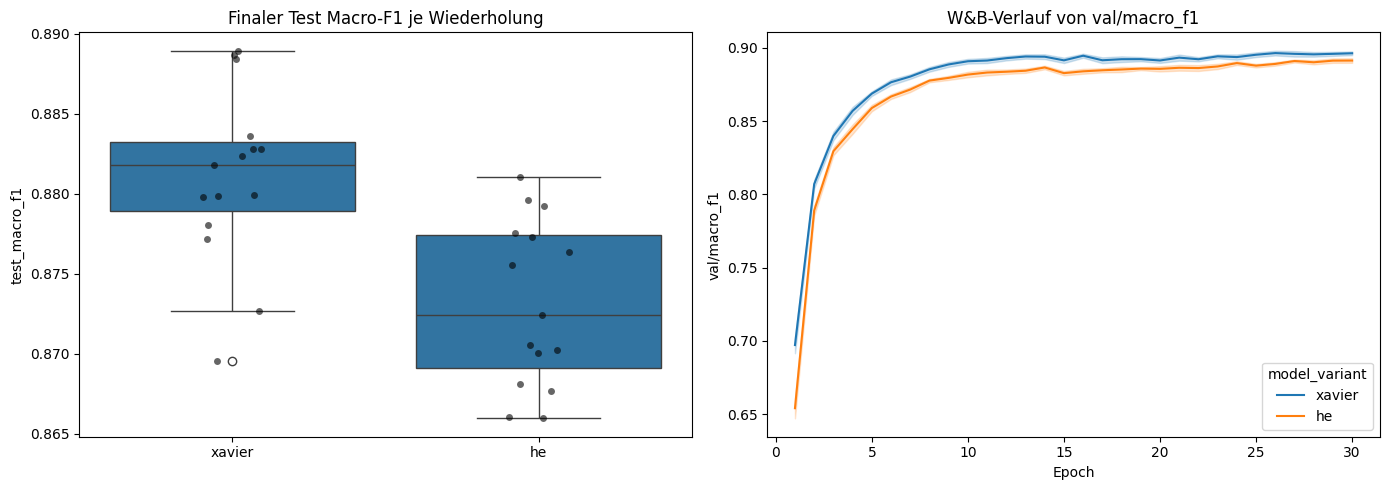

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp08_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['xavier', 'he'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp08_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['xavier', 'he'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp08_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [101]:
# H_0: Xavier is better or equal to He initialization, H_1: He is better than Xavier initialization

xavier_f1 = (
    hyp08_runs_df[hyp08_runs_df["model_variant"] == "xavier"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
he_f1 = (
    hyp08_runs_df[hyp08_runs_df["model_variant"] == "he"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_08 = wilcoxon(
    x=xavier_f1,
    y=he_f1,
    alternative="less"
)

print(f"xavier Mean: {xavier_f1.mean():.4f}")
print(f"he Mean: {he_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_08.statistic}, p-value={wilcoxon_result_08.pvalue}")

xavier Mean: 0.8811
he Mean: 0.8732
Wilcoxon signed-rank test result: statistic=120.0, p-value=1.0


#### Interpretation

Die Hypothese wird nicht bestätigt. Entgegen der Erwartung erzielt He-Initialisierung keinen Vorteil gegenüber Xavier. Xavier erreicht einen mittleren Test-Macro-F1 von 0.8811, während He nur 0.8732 erreicht. Der einseitige Wilcoxon-Test für die Annahme, dass He besser ist, ergibt p = 1.0. Die Nullhypothese kann daher nicht verworfen werden.

Theoretisch wäre He-Initialisierung bei ReLU-Aktivierungen plausibel, da sie die Varianz der Aktivierungen besser erhalten soll. In diesem konkreten Setup scheint dieser Vorteil jedoch nicht einzutreten. Eine mögliche Erklärung ist, dass die Baseline zu flach ist und das Varianzproblem deshalb weniger stark auftritt. Zusätzlich kann He durch die grössere Initialisierungsvarianz stärkere Aktivierungen und grössere Gradienten erzeugen. In Kombination mit der gewählten Lernrate kann dies die Optimierung eher destabilisieren.

### Hypothese 9: Optimizer
Die Modelloptimierung via Adam verbessert die Modelperformance und stabilisiert das training auf dem SVHN-Datensatz.

$H_0: F(M_{\text{Adam}}) \leq F(M_{\text{SGD}})$

$H_1: F(M_{\text{Adam}}) > F(M_{\text{SGD}})$

#### Begründung
Während der standardmässige SGD-Optimizer eine feste globale Lernrate auf alle Parameter anwendet, nutzt Adam (Adaptive Moment Estimation) adaptive Lernraten pro Parameter auf Basis der ersten und zweiten Momente der Gradienten. Die Formel lautet:

$$
x_{t+1} = x_t - \eta \frac{\hat m_t}{(\sqrt{\hat v_t} + \epsilon)}, 
$$

Wobei:  
$m_t = \beta_1 m_{t-1} + (1-\beta_1)g_t$;       Erstes Moment / Momentum  
$v_t = \beta_2 v_{t-1} + (1-\beta_2)g_t^2$;     Zweites unzentriertes Moment / RMSprop-Term  
$\hat m_t = \frac{m_t}{(1-\beta_1^t)}$;         Bias-Korrektur für das erste Moment  
$\hat v_t = \frac{v_t}{1-\beta_2^t}$;           Bias-Korrektur für das zweite Moment  
$\eta = 0.01$;                                  Lernrate  

Dies macht Adam besonders effizient bei verrauschten Gradienten oder komplexen Verlustlandschaften. Durch diese adaptive Anpassung wird ein beschleunigter Lernfortschritt in den frühen Phasen des Trainings sowie ein mindestens leicht höherer finaler Macro-$F_{1}$-Score erwartet.

#### Implementierung

- Trainingslogik mit optionaler Optimizer-Factory: [src/deeplearning/training.py](../src/deeplearning/training.py)
- Experiment-Runner: [src/hyp_tests/Hypothese_09.py](../src/hyp_tests/Hypothese_09.py)

Die gemeinsame Baseline dient hier direkt als Referenzmodell $M_{\text{SGD}}$, da sie bereits mit `SGD` trainiert wird und mit der besten Tuning-Konfiguration aus dem Notebook gespeichert ist (`learning_rate=0.05`, `batch_size=128`, `epochs=30`).

Fuer $M_{\text{Adam}}$ bleibt das Modell identisch zum Baseline-CNN; veraendert wird ausschliesslich der Optimizer von `SGD` auf `Adam`. 
Zusätzlich musste ich dabei meine learningrate für massiv nach unten anpassen, da Adam durch die Akkumulation der quadrierten Gradienten im Nenner zu deutlich grösseren effektiven Update-Schritten neigt. 
Eine Beibehaltung der SGD-Lernrate von 0.05 hätte hier zu instabilen Gewichtsaktualisierungen, explodierenden Gradienten und einem verfrühten Divergieren des Modells geführt, also einer massiven vershclechterung.

Korrekt wäre es gewesen, eine neue GridSearch mit ADAM auszuführen. Dies ist aus Zeitgründen leider nicht ganz möglich.

In [102]:
hyp09_runs_path = results_dir / "hypothesis_09_runs.csv"
hyp09_summary_path = results_dir / "hypothesis_09_summary.json"

hyp09_variant_runs_df = pd.read_csv(hyp09_runs_path)
hyp09_runs_df = pd.concat([baseline_runs_df, hyp09_variant_runs_df], ignore_index=True)


hypothese_09_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_09",
            "config.is_summary_run": False,
        },
    )
)

In [103]:
hyp09_wandb_runs = baseline_wandb_runs + hypothese_09_variant_wandb_runs

hyp09_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp09_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp09_history_frames = []
for run in hyp09_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp09_history_frames.append(history)

hyp09_history_df = pd.concat(hyp09_history_frames, ignore_index=True)

display(hyp09_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
15,b8fxwr76,Hypothese_09-adam-repeat-01,adam,1,0.917704,0.904048,0.922594,0.871775
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
16,ba6h7bq2,Hypothese_09-adam-repeat-02,adam,2,0.914653,0.908861,0.920683,1.004498
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
17,l9ylel9z,Hypothese_09-adam-repeat-03,adam,3,0.916975,0.899853,0.921229,0.983953
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
18,m9nfgfz9,Hypothese_09-adam-repeat-04,adam,4,0.908974,0.905169,0.914949,1.044501
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
19,rjhaowyq,Hypothese_09-adam-repeat-05,adam,5,0.909617,0.902965,0.917679,0.976638
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896


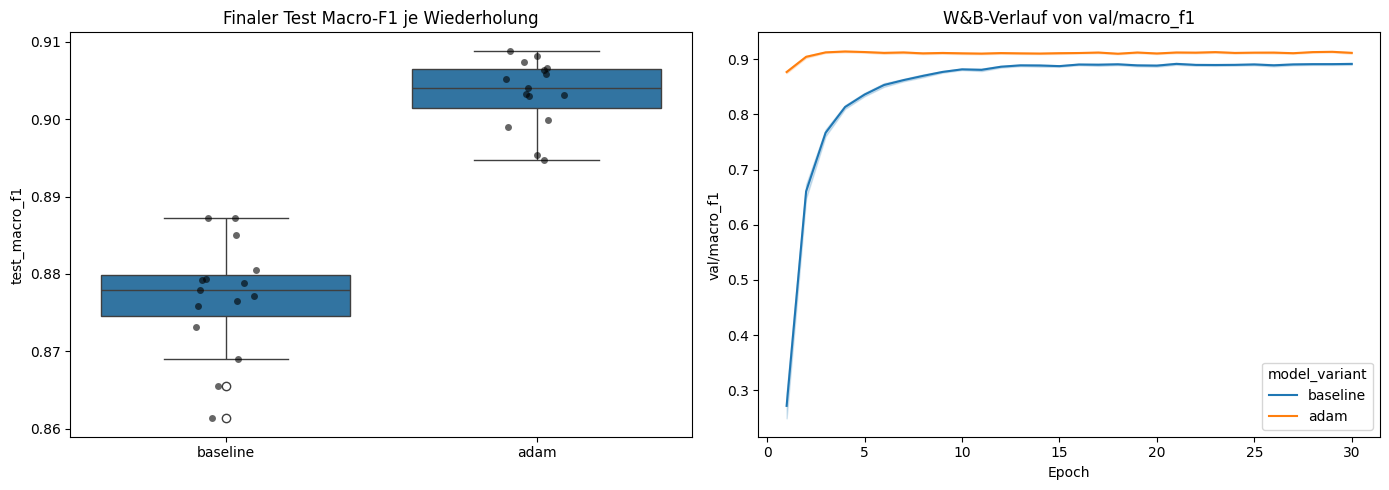

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp09_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'adam'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp09_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'adam'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)

axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp09_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [105]:
# H_0: Adam is better or equal to SGD optimizer, H_1: SGD is better than Adam optimizer

baseline_h9_f1 = (
    hyp09_runs_df[hyp09_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
adam_f1 = (
    hyp09_runs_df[hyp09_runs_df["model_variant"] == "adam"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_09 = wilcoxon(
    x=baseline_h9_f1,
    y=adam_f1,
    alternative="less"
)

print(f"baseline Mean: {baseline_h9_f1.mean():.4f}")
print(f"adam Mean: {adam_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_09.statistic}, p-value={wilcoxon_result_09.pvalue}")

baseline Mean: 0.8769
adam Mean: 0.9034
Wilcoxon signed-rank test result: statistic=0.0, p-value=3.0517578125e-05


#### Interpretation

Die Hypothese wird bestätigt. Adam verbessert den mittleren Test-Macro-F1-Score von 0,8769 auf 0,9034 und der Wilcoxon-Test ist mit p = 3,05e-05 signifikant. Adam scheint in diesem Setup die Optimierung deutlich zu stabilisieren und schneller zu besseren Lösungen zu führen als SGD ohne Momentum.

Dieser Vorteil ist plausibel, da Adam adaptive Lernraten pro Parameter verwendet und dadurch weniger empfindlich auf unterschiedliche Gradientenskalen reagiert. Gerade bei CNNs mit mehreren Layern kann dies von Vorteil sein, wenn einige Parameter sehr kleine und andere sehr große Gradienten erhalten.

Methodisch muss jedoch angemerkt werden, dass nicht nur der Optimizer geändert, sondern auch die Lernrate angepasst wurde. Der Vergleich zeigt daher nicht „Adam gegen SGD bei identischer Lernrate“, sondern „eine praktikable Adam-Konfiguration schlägt die gewählte SGD-Baseline“. Für einen vollständig fairen Vergleich müsste für beide Optimierer eine eigene Lernratenoptimierung durchgeführt werden.

### Hypothese 10: Transfer Learning 

Ein auf ImageNet vortrainiertes ResNet18-Modell erzielt eine höhere Performance auf dem SVHN-Datensatz als das von Grund auf trainierte Baseline-Modell.

$H_0: F(M_{\text{TL}}) \leq F(B)$

$H_1: F(M_{\text{TL}}) > F(B)$

#### Begründung
Das auf ImageNet vortrainierte ResNet18-Backbone verfügt bereits über hochgradig optimierte Filter zur Extraktion universeller visueller Merkmale (wie Kanten, Formen und Texturen). Da diese Primitiva auch für die Erkennung von SVHN-Ziffern fundamental sind, startet das Modell in einem bereits funktionellen lokalen Minimum des Parameterraums, während die Baseline diese Repräsentationen zeitaufwendig von Grund auf erlernen muss.  
Dadurch reduziert sich das Optimierungsproblem bei $M_{\text{TL}}$ primär auf die Anpassung des Klassifikationskopfes, wofür dann auc mehr Daten zur verfügung stehen. 
Das fundierte Vorwissen wirkt zudem wie ein Regularisierer, der Overfitting minimiert.

#### Implementierung

- Modellvarianten: [src/deeplearning/model.py:280](../src/deeplearning/model.py:280)
- Experiment-Runner: [src/hyp_tests/Hypothese_10.py](../src/hyp_tests/Hypothese_10.py)

Die gemeinsame Baseline wird wiederverwendet und mit derselben besten Tuning-Konfiguration aus dem Notebook verglichen (`learning_rate=0.05`, `batch_size=128`, `epochs=30`).

Fuer $M_{\text{TL}}$ wird das Baseline-CNN durch ein vortrainiertes `ResNet18` ersetzt:
- das Backbone startet mit ImageNet-Gewichten,
- nur der finale Klassifikationskopf wird fuer die 10 SVHN-Klassen neu trainiert,
- die Eingabebilder werden auf `224 x 224` skaliert und mit den ImageNet-Normalisierungswerten normalisiert.

In [106]:
hyp10_runs_path = results_dir / "hypothesis_10_runs.csv"
hyp10_summary_path = results_dir / "hypothesis_10_summary.json"

hyp10_variant_runs_df = pd.read_csv(hyp10_runs_path)
hyp10_runs_df = pd.concat([baseline_runs_df, hyp10_variant_runs_df], ignore_index=True)


hypothese_10_variant_wandb_runs = list(
    api.runs(
        path=project_path,
        filters={
            "config.experiment_name": "Hypothese_10",
            "config.is_summary_run": False,
        },
    )
)

In [107]:
hyp10_wandb_runs = baseline_wandb_runs + hypothese_10_variant_wandb_runs

hyp10_wandb_final_df = pd.DataFrame(
    [
        {
            "run_id": run.id,
            "run_name": run.name,
            "model_variant": run.config.get("model_variant"),
            "repeat_idx": run.config.get("repeat_idx"),
            "val_macro_f1": run.summary.get("val/macro_f1"),
            "test_macro_f1": run.summary.get("test/macro_f1"),
            "val_accuracy": run.summary.get("val/accuracy"),
            "val_loss": run.summary.get("val/loss"),
        }
        for run in hyp10_wandb_runs
    ]
).sort_values(["repeat_idx", "model_variant"])

hyp10_history_frames = []
for run in hyp10_wandb_runs:
    history = run.history(keys=["_step", "val/macro_f1"], pandas=True).dropna(how="all")
    history = history[["_step", "val/macro_f1"]].copy()
    history["model_variant"] = run.config.get("model_variant")
    history["repeat_idx"] = run.config.get("repeat_idx")
    hyp10_history_frames.append(history)

hyp10_history_df = pd.concat(hyp10_history_frames, ignore_index=True)

display(hyp10_wandb_final_df)

,run_id,run_name,model_variant,repeat_idx,val_macro_f1,test_macro_f1,val_accuracy,val_loss
0,902yqm08,Baseline_HypTests-repeat-01,baseline,1,0.900257,0.887229,0.907031,0.711000
15,4zgjl2m1,Hypothese_10-transfer-learning-repeat-01,transfer-learning,1,0.596145,0.609721,0.610922,1.161819
1,wu3m1t2k,Baseline_HypTests-repeat-02,baseline,2,0.893875,0.879313,0.900614,0.754213
16,9ougc8x4,Hypothese_10-transfer-learning-repeat-02,transfer-learning,2,0.589453,0.601157,0.612833,1.159440
2,i6upbzqx,Baseline_HypTests-repeat-03,baseline,3,0.891466,0.861320,0.897611,0.671018
17,2nuohcuq,Hypothese_10-transfer-learning-repeat-03,transfer-learning,3,0.601756,0.600862,0.617884,1.154591
3,yp4asvig,Baseline_HypTests-repeat-04,baseline,4,0.891753,0.880454,0.899113,0.808463
18,izwvrrty,Hypothese_10-transfer-learning-repeat-04,transfer-learning,4,0.609780,0.615837,0.627713,1.134322
4,pk8snkpr,Baseline_HypTests-repeat-05,baseline,5,0.878139,0.869005,0.887099,0.839896
19,0y4laswd,Hypothese_10-transfer-learning-repeat-05,transfer-learning,5,0.584724,0.591500,0.606689,1.163065


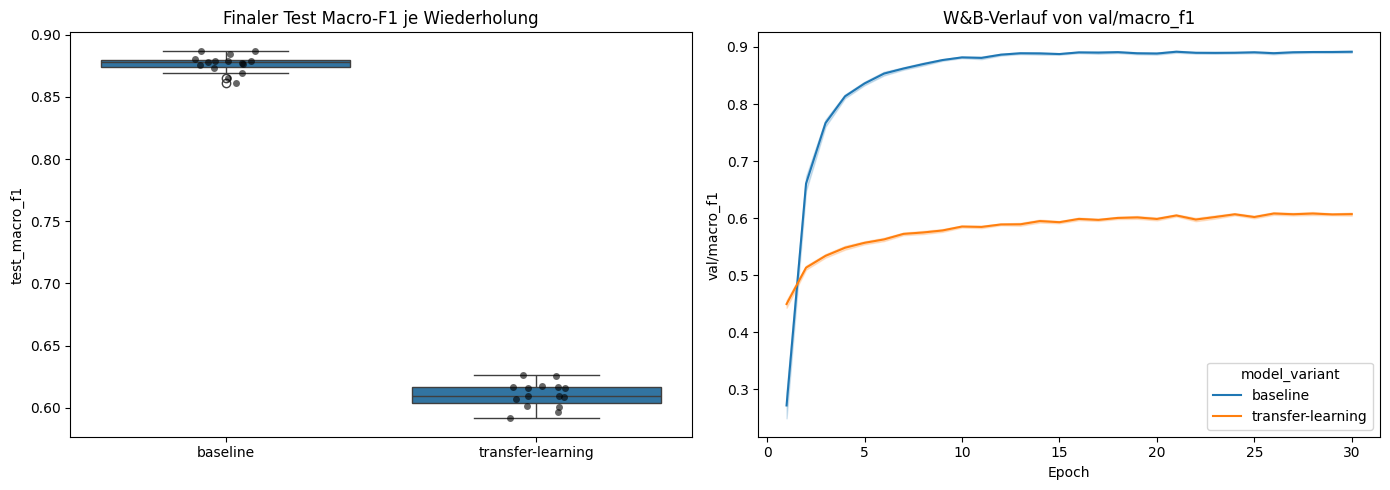

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=hyp10_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'transfer-learning'],
    ax=axes[0],
)
sns.stripplot(
    data=hyp10_runs_df,
    x="model_variant",
    y="test_macro_f1",
    order=['baseline', 'transfer-learning'],
    color="black",
    alpha=0.6,
    ax=axes[0],
)
axes[0].set_title("Finaler Test Macro-F1 je Wiederholung")
axes[0].set_xlabel("")
axes[0].set_ylabel("test_macro_f1")

sns.lineplot(
    data=hyp10_history_df,
    x="_step",
    y="val/macro_f1",
    hue="model_variant",
    estimator="mean",
    errorbar="se",
    ax=axes[1],
)
axes[1].set_title("W&B-Verlauf von val/macro_f1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("val/macro_f1")

plt.tight_layout()
plt.show()


In [109]:
# H_0: Transfer learning is worse or equal to training from scratch, H_1: Training from scratch is worse than transfer learning

baseline_h10_f1 = (
    hyp10_runs_df[hyp10_runs_df["model_variant"] == "baseline"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)
transfer_learning_f1 = (
    hyp10_runs_df[hyp10_runs_df["model_variant"] ==  "transfer-learning"]
    .sort_values("repeat_idx")["test_macro_f1"]
    .reset_index(drop=True)
)

wilcoxon_result_10 = wilcoxon(
    x=baseline_h10_f1,
    y=transfer_learning_f1,
    alternative="less"
)

print(f"baseline Mean: {baseline_h10_f1.mean():.4f}")
print(f"transfer-learning Mean: {transfer_learning_f1.mean():.4f}")
print(f"Wilcoxon signed-rank test result: statistic={wilcoxon_result_10.statistic}, p-value={wilcoxon_result_10.pvalue}")

baseline Mean: 0.8769
transfer-learning Mean: 0.6106
Wilcoxon signed-rank test result: statistic=120.0, p-value=1.0


#### Interpretation
Die Hypothese wird klar nicht bestätigt. Das Transfer-Learning-Modell erreicht lediglich einen mittleren Test-Macro-F1-Wert von 0,6106, während der Wert der Baseline bei 0,8769 liegt. Der einseitige Wilcoxon-Test zur Annahme, dass Transfer Learning besser ist, ergibt p = 1,0, sodass die Nullhypothese nicht verworfen werden kann. Deskriptiv ist sogar das Gegenteil zu beobachten.

Eine mögliche Erklärung liegt im starken Domänenunterschied. ResNet18 wurde auf ImageNet, also auf natürlichen Bildern mit Objektklassen, vortrainiert, während SVHN aus kleinen 32 x 32 Ziffernbildern besteht. Die für ImageNet nützlichen Merkmale sind für die Ziffernklassifikation nur begrenzt geeignet. Zusätzlich müssen die SVHN-Bilder auf 224 x 224 hochskaliert werden, was zu Interpolationsartefakten und einer unnatürlichen Eingabestruktur führen kann.

Ein weiterer Punkt ist, dass nur der finale Klassifikationskopf trainiert wurde. Dadurch bleiben die vortrainierten Feature-Extractor stark auf ImageNet ausgerichtet. Für SVHN wäre es vermutlich sinnvoller, die letzten ResNet-Blöcke zu feinabstimmen oder ein kleineres, auf 32 x 32 Bilder angepasstes CNN zu verwenden.

## Fazit

Insgesamt zeigt sich, dass Verbesserungen vor allem durch Regularisierung, eine robustere Dateneingabe und eine stabilere Optimierung erreicht werden. Den größten Effekt liefert Data Augmentation, gefolgt von Adam, Batch Normalization und Dropout. Reine Architekturänderungen, wie zusätzliche Tiefe, kleinere Kernel oder späteres Pooling, verbessern das Modell dagegen nicht automatisch und können dessen Leistung sogar verschlechtern.

Dies zeigt, dass die Komplexität eines Modells allein kein Garant für eine bessere Performance ist. Für diesen Datensatz scheint eine moderate CNN-Architektur bereits gut geeignet zu sein. Entscheidend ist, dass das Training stabil bleibt und das Modell sich nicht zu stark an trainingsspezifische Bilddetails anpasst.

Wichtig anzumerken ist, dass diese Ergebnisse nur als experimentelle Evidenz innerhalb dieses Setups (diese Modelle auf diesen Daten) gültig sind und nicht als allgemeingültige Aussagen verstanden werden dürfen.